In [ ]:
import marimo as mo

# industrial_master_v2 — plantilla GOOD/BAD: SAM destilado + DINO-masked + EffAD + fusion OOF
Sucesor de `industrial_master.py`. Generaliza el pipeline ganador probado en
`industrial_sam31_distill.py` (transistor_binary): un segmentador SAM se usa una sola vez
como **teacher** para destilar un estudiante EfficientViT-SAM pequeno y rapido; el estudiante
segmenta en produccion. DINOv2 (variante enmascarada) + EfficientAd se funden con alpha
calibrado out-of-fold. Para otra pieza: cambia §1 (`PROJECT_NAME`, `DATA_ROOT`, `SAM_PROMPT`)
y corre de arriba a abajo.
Profiling pesado (Nsight/NVTX, comparacion ONNX-CPU) vive aparte en `industrial_profile.py`;
aqui solo hay un chequeo de latencia resumido (§15).

### §1 Config: todo lo que se edita por pieza nueva vive aqui

In [ ]:
# §1 Proposito: TODA la configuracion en un solo lugar + logs tic/toc. Lo unico que se edita por pieza.
from pathlib import Path

PROJECT_NAME = "transistor_binary"  # cambia por pieza, p.ej. "tuerca_m10"
DATA_ROOT = Path("data/processed/transistor_binary")
GOOD_DIR = DATA_ROOT / "good"  # solo cambiar estas dos carpetas por pieza
BAD_DIR = DATA_ROOT / "bad"
SAM_PROMPT = "transistor"  # texto que el teacher SAM busca localizar; cambia por pieza
BACKBONE_ID = "facebook/dinov2-base"
SAM_CHECKPOINT = "models/sam3.1_multiplex.pt"  # peso local gated (descargar de facebook/sam3.1 una vez)
EVIT_NAME = "efficientvit-sam-l1"
EVIT_REPO = Path("models") / PROJECT_NAME / "sam_distillation" / "vendor" / "efficientvit"
EVIT_WEIGHTS = Path("models") / PROJECT_NAME / "sam_distillation" / "pretrained"
EVIT_SIDE = 512
EVIT_EPOCHS = 30
EVIT_BATCH = 2
EVIT_LR = 1e-5  # FP32: FP16/BF16 dieron perdida no finita en esta arquitectura
EVIT_VAL_FRAC = 0.2  # val sale SOLO del split train; el test nunca entra a la destilacion
EVIT_IMPORT_CKPT = None  # ruta a un best.pt ya destilado para saltarte el entreno (mismo fingerprint)
EFFAD_SIZE = "medium"
STEPS = 5000
DINO_VARIANT = "masked"
EFFAD_VARIANT = "none"
assert DINO_VARIANT == "masked" and EFFAD_VARIANT == "none", "variantes fijadas: el pipeline asume dino=masked, effad=none"
PREPROC_VERSION = 1  # subir al cambiar build_masked/variant_image: invalida la cache DINO
TEST_SIZE = 0.2
SEED = 42
N_SPLITS = 3  # folds para cv_splits() (OOF de §10); sube si el dataset es mas grande
FROZEN = {"preproc": 1, "backbone": "facebook/dinov2-base", "dino_variant": "masked",
          "effad_variant": "none", "test_size": 0.2, "seed": 42,
          "alpha_src": "oof", "cut_src": "oof"}
assert (PREPROC_VERSION, BACKBONE_ID, DINO_VARIANT, EFFAD_VARIANT, TEST_SIZE, SEED) == (
    FROZEN["preproc"], FROZEN["backbone"], FROZEN["dino_variant"], FROZEN["effad_variant"], FROZEN["test_size"], FROZEN["seed"]), "tocaste la config congelada"
SAM_PADDING = 0.08
MIN_MASK_AREA_RATIO = 0.03
MAX_MASK_AREA_RATIO = 0.85
N_BOOT = 200
MLFLOW_URI = "sqlite:///mlflow.db"
MLFLOW_EXPERIMENT = PROJECT_NAME
MODELS_DIR = Path("models") / PROJECT_NAME / "industrial_master_v2"  # dir propio: "prod/" y las figuras base ya tienen archivos trackeados de otros pipelines
FIG_DIR = Path("reports/figures") / PROJECT_NAME / "industrial_master_v2"
FIG_DIR.mkdir(parents=True, exist_ok=True)
MIN_RECALL_FOR_PILOT = 0.98
MAX_FAR_FOR_PILOT = 0.08
EQUIV_N_SAMPLES = 20  # imagenes de test muestreadas en el chequeo de equivalencia (§14)
LATENCY_N_IMAGES = 20
LATENCY_N_WARMUP = 5

import time as _tlog
TIC = {}

def tic(name):
    TIC[name] = _tlog.time()
    print("[%s] inicio %s" % (_tlog.strftime("%H:%M:%S"), name), flush=True)

def toc(name):
    _dt = _tlog.time() - TIC.pop(name, _tlog.time())
    print("[%s] fin %s (%.1fs)" % (_tlog.strftime("%H:%M:%S"), name, _dt), flush=True)
import numpy as np
import pandas as pd
import hashlib
import matplotlib.pyplot as plt

### §2 Datos: escanea carpetas (+ labels.csv opcional), fingerprint, split y cv_splits()

In [ ]:
# §2 Proposito: inventario del dataset (filename, label, path [, group, defect]) + split train/test
# + fingerprint + cv_splits() compartido (StratifiedGroupKFold si hay columna de grupo).
from sklearn.model_selection import StratifiedShuffleSplit

_recs = [{"filename": p.name, "label": "good", "path": str(p)} for p in sorted(GOOD_DIR.glob("*")) if p.is_file()]
_recs += [{"filename": p.name, "label": "bad", "path": str(p)} for p in sorted(BAD_DIR.glob("*")) if p.is_file()]
assert _recs, f"carpetas vacias: {GOOD_DIR} {BAD_DIR}"
df_files = pd.DataFrame(_recs)
assert not df_files.filename.duplicated().any(), "filenames duplicados entre good/bad"

group_col = None
has_defect = False
_labels_csv = DATA_ROOT / "labels.csv"
if _labels_csv.exists():
    _meta = pd.read_csv(_labels_csv)
    group_col = next((c for c in ("part_id", "lot", "group") if c in _meta.columns), None)
    has_defect = "defect" in _meta.columns
    _cols = ["filename"] + [c for c in (group_col, "defect") if c]
    df_files = df_files.merge(_meta[_cols], on="filename", how="left")
    print("labels.csv: group_col=%s has_defect=%s" % (group_col, has_defect))

print(f"dataset: {(df_files.label == 'good').sum()} GOOD + {(df_files.label == 'bad').sum()} BAD")
fingerprint = hashlib.sha1("|".join(sorted(f"{r.filename}:{(GOOD_DIR / r.filename if r.label == 'good' else BAD_DIR / r.filename).stat().st_size}" for r in df_files.itertuples())).encode()).hexdigest()[:16]
print("fingerprint:", fingerprint)
_y0 = (df_files.label == "bad").to_numpy(int)
_tr, _te = next(StratifiedShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=SEED).split(df_files, _y0))
train_files = df_files.iloc[_tr].reset_index(drop=True)
test_files = df_files.iloc[_te].reset_index(drop=True)
print(f"split: {len(train_files)} train ({(train_files.label == 'bad').sum()} BAD) + {len(test_files)} test ({(test_files.label == 'bad').sum()} BAD)")
if group_col is not None and train_files[group_col].notna().any():
    print(f"columna de grupo detectada: '{group_col}' -> cv_splits() usara StratifiedGroupKFold")
MODELS_DIR.mkdir(parents=True, exist_ok=True)

def cv_splits(y, groups=None, seed=SEED):
    # Generalizacion de industrial_master.py: toma `groups` explicito (alineado a `y`) en vez de
    # cerrar sobre una columna de tamano fijo, para poder usarse tanto en el dataset completo
    # como en subconjuntos (p.ej. solo train en la calibracion OOF de §10).
    from sklearn.model_selection import StratifiedKFold as _SK
    if groups is None:
        return list(_SK(n_splits=N_SPLITS, shuffle=True, random_state=seed).split(y, y))
    from sklearn.model_selection import StratifiedGroupKFold as _SGK
    try:
        return list(_SGK(n_splits=N_SPLITS).split(y, y, groups=groups))
    except ValueError as _e:
        print(f"WARN grupos insuficientes ({_e}): fallback StratifiedKFold")
        return list(_SK(n_splits=N_SPLITS, shuffle=True, random_state=seed).split(y, y))

labels.csv: group_col=None has_defect=True
dataset: 273 GOOD + 40 BAD
fingerprint: 943ae352501916c0
split: 250 train (32 BAD) + 63 test (8 BAD)


### §2b Ejemplos del dataset: cómo se ven las piezas GOOD y BAD
4 GOOD al azar y 4 BAD (un defecto distinto por pieza cuando `labels.csv` trae la columna `defect`). Sirve para ver qué es "malo" antes de segmentar o clasificar.

[15:40:32] inicio ejemplos_dataset
BAD por defecto: {'bent_lead': 10, 'cut_lead': 10, 'damaged_case': 10, 'misplaced': 10}
saved ejemplos_dataset.png
[15:40:33] fin ejemplos_dataset (0.5s)



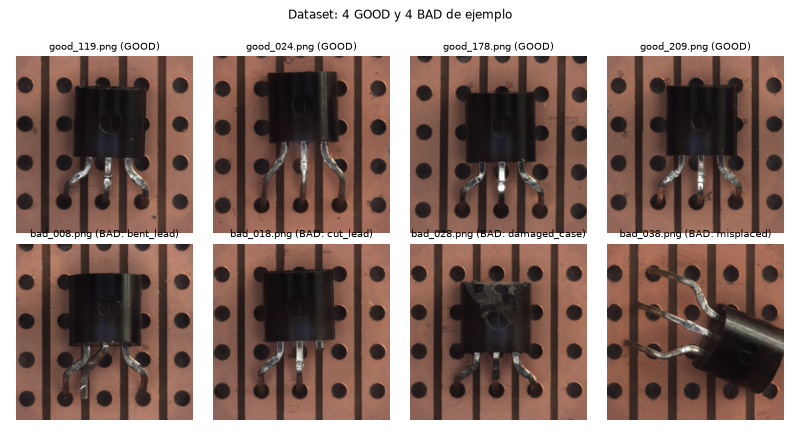

In [ ]:
# §2b Proposito: ejemplos del dataset: 4 GOOD y 4 BAD (un tipo de defecto distinto por BAD si hay columna defect).
tic("ejemplos_dataset")
_rng = np.random.default_rng(SEED)
_good = df_files[df_files.label == "good"].reset_index(drop=True)
_bad = df_files[df_files.label == "bad"].reset_index(drop=True)
_g = [_good.iloc[int(_k)] for _k in _rng.choice(len(_good), size=min(4, len(_good)), replace=False)]
_b = []
if has_defect:
    print("BAD por defecto:", _bad.defect.value_counts().to_dict())
    for _dv in sorted(_bad.defect.dropna().unique())[:4]:
        _b.append(_bad[_bad.defect == _dv].sample(1, random_state=SEED).iloc[0])
_seen = {_r.filename for _r in _b}
for _k in _rng.permutation(len(_bad)):
    if len(_b) >= 4:
        break
    _r = _bad.iloc[int(_k)]
    if _r.filename not in _seen:
        _b.append(_r)
        _seen.add(_r.filename)
_fig, _ax = plt.subplots(2, 4, figsize=(10, 5.4))
_fig.patch.set_facecolor("white")
for _c, _r in enumerate(_g):
    _ax[0][_c].imshow(Image.open(_r.path).convert("RGB").resize((256, 256)))
    _ax[0][_c].set_title("%s (GOOD)" % _r.filename, fontsize=9, color="black")
for _c, _r in enumerate(_b):
    _ax[1][_c].imshow(Image.open(_r.path).convert("RGB").resize((256, 256)))
    _ax[1][_c].set_title("%s (BAD%s)" % (_r.filename, (": " + str(_r["defect"])) if has_defect and str(_r["defect"]) != "nan" else ""), fontsize=9, color="black")
[_a.axis("off") for _a in _ax.ravel()]
_fig.suptitle("Dataset: 4 GOOD y 4 BAD de ejemplo", fontsize=11, color="black")
_fig.tight_layout(rect=(0, 0, 1, 0.97))
_png = FIG_DIR / "ejemplos_dataset.png"
_fig.savefig(_png, dpi=80)
plt.close(_fig)
print("saved", _png.name)
toc("ejemplos_dataset")
mo.image(str(_png))

### §3 SAM teacher: segmenta una vez, guarda mascaras y se descarga de la VRAM

In [ ]:
# §3 Proposito: descarga el peso gated de SAM3.1 si no esta en disco (pesa ~3.5 GB, no se trackea en git).
def _ensure_sam_checkpoint(path, repo_id="facebook/sam3.1", filename="sam3.1_multiplex.pt"):
    from pathlib import Path as _P
    _p = _P(path)
    if _p.exists():
        print("SAM3.1 checkpoint ya en disco:", _p)
        return True
    import os as _os
    _token = _os.environ.get("HF_TOKEN") or _os.environ.get("HUGGING_FACE_HUB_TOKEN")
    if not _token:
        _env_file = _P(".env")
        if _env_file.exists():
            for _line in _env_file.read_text(encoding="utf-8").splitlines():
                if _line.strip().startswith("HF_TOKEN="):
                    _token = _line.split("=", 1)[1].strip().strip('"').strip("'")
                    break
    assert _token, "falta HF_TOKEN (env o .env): necesario para el repo gated facebook/sam3.1"
    from huggingface_hub import hf_hub_download
    print("descargando", filename, "de", repo_id, "(~3.5 GB, gated: requiere HF_TOKEN y licencia aceptada)...", flush=True)
    _cached = hf_hub_download(repo_id=repo_id, filename=filename, token=_token)
    _p.parent.mkdir(parents=True, exist_ok=True)
    import shutil as _sh
    _sh.copy2(_cached, _p)
    print("guardado en", _p)
    return True

sam_checkpoint_ok = _ensure_sam_checkpoint(SAM_CHECKPOINT)

SAM3.1 checkpoint ya en disco: models\sam3.1_multiplex.pt


In [ ]:
# §3 Proposito: carga SAM3.1 una vez + funciones mascara/bbox/crop. Solo localiza, nunca clasifica.
import time
from pathlib import Path as _Path

import torch
from PIL import Image
from transformers import AutoImageProcessor, AutoModel
from ultralytics.models.sam import SAM3SemanticPredictor

tic("sam_load")
assert sam_checkpoint_ok and _Path(SAM_CHECKPOINT).exists(), f"falta peso SAM3.1: {SAM_CHECKPOINT} (bajar de facebook/sam3.1)"
SAM_CACHE = {}  # lo llena segment_part, lo vacia unload_sam()
_sam_overrides = {
    "conf": 0.05, "task": "segment", "mode": "predict",
    "model": SAM_CHECKPOINT, "imgsz": 1036, "verbose": False, "save": False,
}
_sam_dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("sam device:", _sam_dev)

def segment_part(image, prompt=SAM_PROMPT):
    _t0 = time.perf_counter()
    _sam = SAM_CACHE.get("predictor")
    if _sam is None:
        _sam = SAM_CACHE["predictor"] = SAM3SemanticPredictor(overrides=_sam_overrides)
        print("SAM construido una vez (%.1fs)" % (time.perf_counter() - _t0), flush=True)
    _sam.set_image(np.asarray(image.convert("RGB"))[:, :, ::-1])
    _r = _sam(text=[prompt])[0]
    if _r.masks is None:
        return {"mask": np.zeros((image.size[1], image.size[0]), bool), "score": 0.0,
                "latency": time.perf_counter() - _t0}
    _qi = int(_r.boxes.conf.cpu().numpy().argmax())
    return {"mask": _r.masks.data[_qi].cpu().numpy().astype(bool),
            "score": float(_r.boxes.conf[_qi]), "latency": time.perf_counter() - _t0}

def mask_to_bbox(mask):
    _ys, _xs = np.where(np.asarray(mask))
    if len(_xs) == 0:
        return None
    return (int(_xs.min()), int(_ys.min()), int(_xs.max()), int(_ys.max()))

def expand_bbox(bbox, image_shape, padding_ratio=0.08):
    _h, _w = image_shape[:2]
    _x0, _y0, _x1, _y1 = bbox
    _bw, _bh = _x1 - _x0, _y1 - _y0
    _px, _py = int(_bw * padding_ratio), int(_bh * padding_ratio)
    return (max(0, _x0 - _px), max(0, _y0 - _py), min(_w, _x1 + _px), min(_h, _y1 + _py))

def unload_sam():
    SAM_CACHE.pop("predictor", None)
    import gc as _gc
    _gc.collect()
    torch.cuda.empty_cache()
    print("sam descargado, VRAM:", round(torch.cuda.memory_allocated() / 1e9, 2), "GB")

toc("sam_load")

[15:40:32] inicio sam_load
sam device: cuda
[15:40:32] fin sam_load (0.0s)


In [ ]:
# §3 Proposito: mascaras teacher de TODO el dataset con log cada 10 (o reusa cache por fingerprint).
# Las PNG a resolucion completa son el TARGET de la destilacion (§4); las 256 son para QC.
tic("teacher_cache")
_t_dir = MODELS_DIR / "teacher"
teacher_mask_dir = _t_dir / "masks"
teacher_mask_dir.mkdir(parents=True, exist_ok=True)
_csv, _pt = _t_dir / "masks.csv", _t_dir / "masks256.pt"
_fp_file = _t_dir / "fingerprint.txt"
_png_ok = all((teacher_mask_dir / _f).is_file() for _f in df_files.filename)
if _csv.exists() and _fp_file.exists() and _fp_file.read_text().strip() == fingerprint and _png_ok:
    teacher_masks = pd.read_csv(_csv)
    _mp = torch.load(_pt, map_location="cpu", weights_only=False)
    teacher_masks256, _mfn = _mp["masks"], _mp["fnames"]
    print(f"teacher cache hit: {len(teacher_masks)} filas + PNG full-res")
else:
    _rows, _ml, _mfn = [], [], []
    for _k, _r in enumerate(df_files.itertuples()):
        _im = Image.open(_r.path).convert("RGB")
        _s = segment_part(_im)
        _bb = mask_to_bbox(_s["mask"])
        _m = _s["mask"]
        _rows.append({"filename": _r.filename, "label": _r.label, "score": round(_s["score"], 3),
                       "area": round(float(_m.mean()), 4), "bbox": _bb is not None,
                       "edge": bool(_m[0, :].any() or _m[-1, :].any() or _m[:, 0].any() or _m[:, -1].any()),
                       "lat": round(_s["latency"], 2),
                       "x0": _bb[0] if _bb else -1, "y0": _bb[1] if _bb else -1,
                       "x1": _bb[2] if _bb else -1, "y1": _bb[3] if _bb else -1})
        Image.fromarray(_m.astype("uint8") * 255).save(teacher_mask_dir / _r.filename)
        _ml.append(torch.from_numpy(np.array(Image.fromarray(_m.astype("uint8") * 255).resize((256, 256))) > 0))
        _mfn.append(_r.filename)
        if (_k + 1) % 10 == 0:
            print(f"teacher {_k + 1}/{len(df_files)}", flush=True)
    teacher_masks = pd.DataFrame(_rows)
    teacher_masks.to_csv(_csv, index=False)
    teacher_masks256 = torch.stack(_ml)
    torch.save({"masks": teacher_masks256, "fnames": _mfn}, _pt)
    _fp_file.write_text(fingerprint)
    print(f"saved {len(teacher_masks)} mascaras teacher (csv + PNG + 256)")
print(f"bbox_ok={teacher_masks.bbox.mean():.3f} edge={teacher_masks.edge.mean():.3f} lat_media={teacher_masks.lat.mean():.2f}s total={teacher_masks.lat.sum() / 60:.1f}min")
unload_sam()
toc("teacher_cache")

[15:40:33] inicio teacher_cache
teacher cache hit: 313 filas + PNG full-res
bbox_ok=1.000 edge=0.013 lat_media=1.63s total=8.5min
sam descargado, VRAM: 0.0 GB
[15:40:33] fin teacher_cache (0.2s)


### §4 Destilacion: estudiante EfficientViT-SAM aprende las mascaras del teacher (solo split train)

In [ ]:
# §4 Proposito: deja listo el checkout oficial de EfficientViT (commit fijado) y el peso preentrenado
# del estudiante si no existen. Ninguno va en git (peso ~100 MB, repo vendorizado).
def _ensure_efficientvit_assets(repo_dir, weights_dir, evit_name):
    import hashlib as _hl
    import subprocess as _sp
    from pathlib import Path as _P
    _target_commit = "412c2e11f5a84ef4d6913cece509e7167d6939e1"
    _repo, _wdir = _P(repo_dir).resolve(), _P(weights_dir).resolve()
    if not (_repo / ".git").is_dir():
        assert not _repo.exists(), "la ruta de EfficientViT existe pero no es un checkout Git: " + str(_repo)
        _repo.parent.mkdir(parents=True, exist_ok=True)
        print("clonando EfficientViT oficial...", flush=True)
        _sp.run(["git", "clone", "--depth", "1", "https://github.com/mit-han-lab/efficientvit.git", str(_repo)], check=True)
    _head = _sp.run(["git", "-C", str(_repo), "rev-parse", "HEAD"], capture_output=True, text=True, check=True).stdout.strip()
    if _head != _target_commit:
        assert _sp.run(["git", "-C", str(_repo), "diff", "--quiet"]).returncode == 0, "checkout con cambios: no se sobrescribe"
        for _cmd in (["git", "-C", str(_repo), "fetch", "--depth", "1", "origin", _target_commit],
                     ["git", "-C", str(_repo), "checkout", "--detach", _target_commit]):
            _sp.run(_cmd, check=True)
    print("efficientvit en commit", _target_commit[:10])
    _fname = evit_name.replace("-", "_") + ".pt"
    _wfile = _wdir / _fname
    if not _wfile.is_file():
        from huggingface_hub import HfApi, hf_hub_download
        _wdir.mkdir(parents=True, exist_ok=True)
        _info = HfApi().model_info("mit-han-lab/efficientvit-sam", files_metadata=True, token=False)
        _lfs = {e.rfilename: e.lfs for e in _info.siblings}[_fname]
        _expected = _lfs.get("sha256") if isinstance(_lfs, dict) else getattr(_lfs, "sha256", None)
        print("descargando", _fname, "...", flush=True)
        _dl = _P(hf_hub_download(repo_id="mit-han-lab/efficientvit-sam", filename=_fname, revision=_info.sha,
                                 local_dir=str(_wdir), token=False))
        _h = _hl.sha256()
        with _dl.open("rb") as _fh:
            for _chunk in iter(lambda: _fh.read(1 << 20), b""):
                _h.update(_chunk)
        assert _expected and _h.hexdigest() == _expected, "SHA-256 incorrecto para " + _fname
        print(_fname, "verificado,", _dl.stat().st_size, "bytes")
    else:
        print("peso ya en disco:", _wfile)
    return True

evit_assets_ok = _ensure_efficientvit_assets(EVIT_REPO, EVIT_WEIGHTS, EVIT_NAME)

efficientvit en commit 412c2e11f5
peso ya en disco: C:\Users\user\Documents\qc-vision-inspector\models\transistor_binary\sam_distillation\pretrained\efficientvit_sam_l1.pt


In [ ]:
# §4 Proposito: helpers del estudiante (carga, letterbox, target, metricas de mascara).
# El decoder recibe SIEMPRE una caja fija de cuadro completo: nunca la caja real del teacher,
# para que el estudiante aprenda a localizar solo y la inferencia no necesite oracle.
import sys as _sys
import torch.nn.functional as TF

class Student(torch.nn.Module):
    def __init__(self, _core):
        super().__init__()
        self.sam = _core

    def forward(self, _x):
        _emb = self.sam.image_encoder(_x)
        _box = _x.new_tensor([[0.0, 0.0, 1024.0, 1024.0]])
        _sparse, _dense = self.sam.prompt_encoder(points=None, boxes=_box, masks=None)
        _logits, _ = self.sam.mask_decoder(
            image_embeddings=_emb, image_pe=self.sam.prompt_encoder.get_dense_pe(),
            sparse_prompt_embeddings=_sparse, dense_prompt_embeddings=_dense,
            multimask_output=False)
        return TF.interpolate(_logits, size=_x.shape[-2:], mode="bilinear", align_corners=False)

def load_student(checkpoint=None):
    _repo = EVIT_REPO.resolve()
    if _repo.is_dir() and str(_repo) not in _sys.path:
        _sys.path.insert(0, str(_repo))
    from efficientvit.sam_model_zoo import create_sam_model

    _w = EVIT_WEIGHTS / (EVIT_NAME.replace("-", "_") + ".pt")
    assert checkpoint is not None or _w.is_file(), f"falta el peso oficial {_w}"
    _core = create_sam_model(name=EVIT_NAME.rsplit("-", 1)[-1], pretrained=checkpoint is None,
                             **({"weight_url": str(_w)} if checkpoint is None else {}))
    _st = Student(_core)
    if checkpoint is not None:
        _st.load_state_dict(torch.load(checkpoint, map_location="cpu", weights_only=True)["state_dict"])
    return _st

def prepare_tensor(image, side):
    # Letterbox centrado + normalizacion ImageNet: identico al entreno (el ckpt depende de esto).
    _h, _w = image.shape[:2]
    _ratio = min(side / _h, side / _w)
    _rh, _rw = round(_h * _ratio), round(_w * _ratio)
    _top, _left = (side - _rh) // 2, (side - _rw) // 2
    _px = torch.from_numpy(image).to("cuda").permute(2, 0, 1).unsqueeze(0)
    _x = TF.interpolate(_px.float(), size=(_rh, _rw), mode="bilinear", align_corners=False)
    _x = TF.pad(_x, (_left, side - _rw - _left, _top, side - _rh - _top), value=0) / 255
    _mean = _x.new_tensor([0.485, 0.456, 0.406])[None, :, None, None]
    _std = _x.new_tensor([0.229, 0.224, 0.225])[None, :, None, None]
    _x = (_x - _mean) / _std
    return _x.contiguous(), (_h, _w, _rh, _rw, _top, _left)

def target_tensor(mask, geometry, side):
    _, _, _rh, _rw, _top, _left = geometry
    _t = torch.from_numpy(np.asarray(mask).astype("float32")).to("cuda")[None, None]
    _t = TF.interpolate(_t, size=(_rh, _rw), mode="nearest")
    return TF.pad(_t, (_left, side - _rw - _left, _top, side - _rh - _top))

def restore_mask(probability, geometry):
    _h, _w, _rh, _rw, _top, _left = geometry
    _m = probability[..., _top:_top + _rh, _left:_left + _rw]
    _m = TF.interpolate(_m.float(), size=(_h, _w), mode="bilinear", align_corners=False)
    return (_m[0, 0] > 0.5).detach().cpu().numpy()

def mask_metrics(prediction, target):
    # Acuerdo con el teacher, NO exactitud frente a etiqueta humana.
    import cv2

    _p, _t = np.asarray(prediction).astype(bool), np.asarray(target).astype(bool)
    assert _p.shape == _t.shape, f"formas distintas {_p.shape} vs {_t.shape}"
    _inter, _union = np.logical_and(_p, _t).sum(), np.logical_or(_p, _t).sum()
    _k, _tol = np.ones((3, 3), np.uint8), np.ones((5, 5), np.uint8)
    _pe = _p & ~cv2.erode(_p.astype(np.uint8), _k).astype(bool)
    _te = _t & ~cv2.erode(_t.astype(np.uint8), _k).astype(bool)
    _prec = float((_pe & cv2.dilate(_te.astype(np.uint8), _tol).astype(bool)).sum() / max(int(_pe.sum()), 1))
    _rec = float((_te & cv2.dilate(_pe.astype(np.uint8), _tol).astype(bool)).sum() / max(int(_te.sum()), 1))
    return {"iou": float(_inter / max(int(_union), 1)),
            "dice": float(2 * _inter / max(int(_p.sum() + _t.sum()), 1)),
            "boundary_f1": 2 * _prec * _rec / max(_prec + _rec, 1e-12),
            "empty_mask": float(not _p.any())}

print("helpers del estudiante listos:", EVIT_NAME)

helpers del estudiante listos: efficientvit-sam-l1


In [ ]:
# §4 Proposito: destila SAM -> estudiante EfficientViT-SAM usando SOLO el split train (test cerrado).
# FP32: FP16/BF16 dieron perdida no finita en esta arquitectura; si una version futura la estabiliza,
# bajar precision y remedir.
import math as _math
import shutil as _shutil
from sklearn.model_selection import StratifiedShuffleSplit as _SSS2

tic("distill_train")
assert evit_assets_ok, "faltan el checkout de EfficientViT y/o su peso preentrenado"
_dir = MODELS_DIR / "student"
_dir.mkdir(parents=True, exist_ok=True)
student_ckpt = _dir / "best.pt"
_resume = _dir / "last_training.pt"
_logcsv = _dir / "light_logs.csv"

if EVIT_IMPORT_CKPT and not student_ckpt.exists():
    _shutil.copy2(EVIT_IMPORT_CKPT, student_ckpt)
    print("importado checkpoint destilado:", EVIT_IMPORT_CKPT, flush=True)

_ytr = (train_files.label == "bad").to_numpy(int)
_tri, _vai = next(_SSS2(n_splits=1, test_size=EVIT_VAL_FRAC, random_state=SEED).split(train_files, _ytr))
_parts = {"train": train_files.iloc[_tri].reset_index(drop=True),
          "val": train_files.iloc[_vai].reset_index(drop=True)}
print(f"destilacion: {len(_parts['train'])} train + {len(_parts['val'])} val, targets = mascaras teacher")

_skip = False
if student_ckpt.exists():
    _meta = torch.load(student_ckpt, map_location="cpu", weights_only=False)
    if _meta.get("fingerprint") is None:
        _skip = True
        print("estudiante importado (sin fingerprint propio): no se reentrena", flush=True)
    elif _meta.get("fingerprint") == fingerprint and _resume.is_file():
        _prog = torch.load(_resume, map_location="cpu", weights_only=False)
        _skip = int(_prog.get("next_epoch", 0)) >= EVIT_EPOCHS
        print(f"progreso previo {_prog.get('next_epoch')}/{EVIT_EPOCHS} -> {'cache hit' if _skip else 'reanuda'}", flush=True)
        del _prog
    else:
        print("checkpoint de otro dataset o sin progreso: reentrena desde el peso oficial", flush=True)

if not _skip:
    _model = load_student().cuda().float()
    _opt = torch.optim.AdamW(_model.parameters(), lr=EVIT_LR, weight_decay=1e-4)
    _rng = np.random.default_rng(SEED)
    _rows, _best_dice, _start = [], -1.0, 0
    if _resume.is_file():
        _sv = torch.load(_resume, map_location="cpu", weights_only=False)
        assert (_sv["fingerprint"] == fingerprint and _sv["batch"] == EVIT_BATCH and _sv.get("side") == EVIT_SIDE and _sv.get("lr") == EVIT_LR and _sv.get("epochs") == EVIT_EPOCHS and _sv.get("val_frac") == EVIT_VAL_FRAC), "resume de otro dataset/hiperparametros"
        _model.load_state_dict(_sv["state_dict"])
        _opt.load_state_dict(_sv["optimizer"])
        _rng.bit_generator.state = _sv["numpy_rng"]
        torch.set_rng_state(_sv["torch_rng"])
        torch.cuda.set_rng_state(_sv["cuda_rng"])
        _rows, _best_dice, _start = _sv["rows"], _sv["best_dice"], int(_sv["next_epoch"])
        print("reanudando en la epoca", _start + 1, flush=True)
        del _sv
    else:
        torch.manual_seed(SEED)
    for _ep in range(_start, EVIT_EPOCHS):
        _em = {}
        for _part in ("train", "val"):
            _training = _part == "train"
            _model.train(_training)
            if _training:
                for _mod in _model.modules():
                    if isinstance(_mod, torch.nn.modules.batchnorm._BatchNorm):
                        _mod.eval()
            _sub = _parts[_part]
            _order = list(_rng.permutation(len(_sub))) if _training else list(range(len(_sub)))
            _losses, _dices = [], []
            for _off in range(0, len(_order), EVIT_BATCH):
                _xs, _ts = [], []
                for _pi in _order[_off:_off + EVIT_BATCH]:
                    _row = _sub.iloc[int(_pi)]
                    _img = np.array(Image.open(_row.path).convert("RGB"), copy=True)
                    _x1, _geo = prepare_tensor(_img, EVIT_SIDE)
                    _t1 = target_tensor(np.array(Image.open(teacher_mask_dir / _row.filename)) > 127, _geo, EVIT_SIDE)
                    if _training and _rng.random() < 0.5:
                        _x1, _t1 = _x1.flip(-1), _t1.flip(-1)
                    _xs.append(_x1)
                    _ts.append(_t1)
                _x, _t = torch.cat(_xs), torch.cat(_ts)
                with torch.set_grad_enabled(_training), torch.autocast("cuda", enabled=False):
                    _logits = _model(_x)
                _prob = _logits.float().sigmoid()
                _sd = (2 * (_prob * _t).sum() + 1) / (_prob.sum() + _t.sum() + 1)
                _loss = TF.binary_cross_entropy_with_logits(_logits.float(), _t) + 1 - _sd
                assert torch.isfinite(_loss), "perdida no finita: no sigas entrenando"
                if _training:
                    _opt.zero_grad(set_to_none=True)
                    _loss.backward()
                    torch.nn.utils.clip_grad_norm_(_model.parameters(), 1.0, error_if_nonfinite=True)
                    _opt.step()
                _losses.append(float(_loss.detach()))
                _dices.append(float(_sd.detach()))
                if (_off // EVIT_BATCH + 1) % 20 == 0:
                    print("ep%d %s lote %d/%d loss=%.4f dice=%.4f" % (
                        _ep + 1, _part, _off // EVIT_BATCH + 1,
                        _math.ceil(len(_order) / EVIT_BATCH), _losses[-1], _dices[-1]), flush=True)
            _em[_part + "_loss"] = float(np.mean(_losses))
            _em[_part + "_dice"] = float(np.mean(_dices))
        _rows.append(dict(epoch=_ep + 1, **_em))
        pd.DataFrame(_rows).to_csv(_logcsv, index=False)
        print(f"epoca {_ep + 1}/{EVIT_EPOCHS} {_em}", flush=True)
        if _em["val_dice"] > _best_dice:
            _best_dice = _em["val_dice"]
            torch.save({"state_dict": {k: v.detach().cpu() for k, v in _model.state_dict().items()},
                        "candidate": EVIT_NAME, "side": EVIT_SIDE, "epoch": _ep + 1,
                        "val_dice": _best_dice, "precision": "fp32", "batch": EVIT_BATCH, "lr": EVIT_LR, "epochs": EVIT_EPOCHS, "val_frac": EVIT_VAL_FRAC,
                        "fingerprint": fingerprint}, student_ckpt)
            print("  nuevo mejor val_dice:", round(_best_dice, 4), flush=True)
        _tmp = _dir / "last_training.tmp"
        torch.save({"state_dict": _model.state_dict(), "optimizer": _opt.state_dict(),
                    "numpy_rng": _rng.bit_generator.state, "torch_rng": torch.get_rng_state(),
                    "cuda_rng": torch.cuda.get_rng_state(), "rows": _rows,
                    "best_dice": _best_dice, "next_epoch": _ep + 1,
                    "fingerprint": fingerprint, "batch": EVIT_BATCH, "side": EVIT_SIDE, "lr": EVIT_LR, "epochs": EVIT_EPOCHS, "val_frac": EVIT_VAL_FRAC}, _tmp)
        _tmp.replace(_resume)
    _model.to("cpu")
    del _model, _opt
    import gc as _gc1

    _gc1.collect()
    torch.cuda.empty_cache()
    print("estudiante entrenado, VRAM:", round(torch.cuda.memory_allocated() / 1e9, 2), "GB")

distill_log = pd.read_csv(_logcsv) if _logcsv.exists() else pd.DataFrame()
assert student_ckpt.exists(), "no hay checkpoint del estudiante"
print("checkpoint:", student_ckpt, "| epocas registradas:", len(distill_log))
toc("distill_train")

[15:40:33] inicio distill_train
destilacion: 200 train + 50 val, targets = mascaras teacher
progreso previo 30/30 -> cache hit
checkpoint: models\transistor_binary\industrial_master_v2\student\best.pt | epocas registradas: 30
[15:40:34] fin distill_train (0.4s)


### §5 Mascaras del estudiante: reemplazan las del teacher en el pipeline + calidad y latencia

In [ ]:
# §5 Proposito: el estudiante segmenta TODO el dataset; de aqui en adelante el pipeline usa
# estas mascaras (mismas columnas que el teacher), nunca mas SAM. Calidad = acuerdo con teacher.
import json as _json1

tic("student_masks")
_sdir = MODELS_DIR / "student"
_csv, _pt = _sdir / "masks.csv", _sdir / "masks256.pt"
_qcsv, _rjson = _sdir / "quality.csv", _sdir / "speed.json"
_ck_sha = hashlib.sha256(student_ckpt.read_bytes()).hexdigest()[:16]
_stamp = f"{fingerprint}:{_ck_sha}"
_fp_file = _sdir / "masks_fingerprint.txt"

if _csv.exists() and _fp_file.exists() and _fp_file.read_text().strip() == _stamp:
    sam_masks = pd.read_csv(_csv)
    _mp2 = torch.load(_pt, map_location="cpu", weights_only=False)
    sam_masks256 = _mp2["masks"]
    student_quality = pd.read_csv(_qcsv)
    student_speed = _json1.loads(_rjson.read_text())
    print(f"student cache hit: {len(sam_masks)} mascaras (ckpt {_ck_sha})")
else:
    _model = load_student(student_ckpt).cuda().float().eval()
    _mdir = _sdir / "masks_png"
    _mdir.mkdir(parents=True, exist_ok=True)
    _warm = [np.array(Image.open(_r.path).convert("RGB"), copy=True) for _r in df_files.head(3).itertuples()]
    with torch.inference_mode():
        for _w in _warm:
            _xw, _gw = prepare_tensor(_w, EVIT_SIDE)
            restore_mask(_model(_xw).float().sigmoid(), _gw)
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()
    _rows, _ml, _qrows, _fwd = [], [], [], []
    import time as _t1

    for _k, _r in enumerate(df_files.itertuples()):
        _img = np.array(Image.open(_r.path).convert("RGB"), copy=True)
        torch.cuda.synchronize()
        _t0 = _t1.perf_counter()
        with torch.inference_mode():
            _x, _geo = prepare_tensor(_img, EVIT_SIDE)
            _prob = _model(_x).float().sigmoid()
            _m = restore_mask(_prob, _geo)
        torch.cuda.synchronize()
        _seg_ms = (_t1.perf_counter() - _t0) * 1000
        _e0, _e1 = torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True)
        with torch.inference_mode():
            _e0.record()
            _ = _model(_x)
            _e1.record()
            _e1.synchronize()
        _fwd.append(_e0.elapsed_time(_e1))
        _bb = mask_to_bbox(_m)
        _rows.append({"filename": _r.filename, "label": _r.label,
                      "score": round(float(_prob.max()), 3),
                      "area": round(float(_m.mean()), 4), "bbox": _bb is not None,
                      "edge": bool(_m[0, :].any() or _m[-1, :].any() or _m[:, 0].any() or _m[:, -1].any()),
                      "lat": round(_seg_ms / 1000, 4),
                      "x0": _bb[0] if _bb else -1, "y0": _bb[1] if _bb else -1,
                      "x1": _bb[2] if _bb else -1, "y1": _bb[3] if _bb else -1,
                      "seg_ms": round(_seg_ms, 2), "fwd_ms": round(_fwd[-1], 2)})
        _ml.append(torch.from_numpy(np.array(Image.fromarray(_m.astype("uint8") * 255).resize((256, 256))) > 0))
        Image.fromarray(_m.astype("uint8") * 255).save(_mdir / _r.filename)
        _tm = np.array(Image.open(teacher_mask_dir / _r.filename)) > 127
        _qrows.append({"filename": _r.filename, "label": _r.label, **mask_metrics(_m, _tm)})
        if (_k + 1) % 25 == 0:
            print(f"student {_k + 1}/{len(df_files)} seg={_seg_ms:.1f}ms iou={_qrows[-1]['iou']:.3f}", flush=True)
    sam_masks = pd.DataFrame(_rows)
    sam_masks.to_csv(_csv, index=False)
    sam_masks256 = torch.stack(_ml)
    torch.save({"masks": sam_masks256, "fnames": list(sam_masks.filename)}, _pt)
    student_quality = pd.DataFrame(_qrows)
    student_quality.to_csv(_qcsv, index=False)
    student_speed = {
        "checkpoint_sha256_16": _ck_sha, "side": EVIT_SIDE, "images": len(sam_masks),
        "fwd_cuda_ms_median": float(np.median(_fwd)), "fwd_cuda_ms_p95": float(np.quantile(_fwd, 0.95)),
        "seg_ms_median": float(sam_masks.seg_ms.median()), "seg_ms_p95": float(sam_masks.seg_ms.quantile(0.95)),
        "teacher_seg_ms_median": float(teacher_masks.lat.median() * 1000),
        "teacher_seg_ms_median_no_first": float(teacher_masks.lat.iloc[1:].median() * 1000),
        "speedup_vs_teacher": float(teacher_masks.lat.median() * 1000 / sam_masks.seg_ms.median()),
        "speedup_vs_teacher_no_first": float(teacher_masks.lat.iloc[1:].median() * 1000 / sam_masks.seg_ms.median()),
        "peak_allocated_gb": torch.cuda.max_memory_allocated() / 1e9,
        "nota": "batch=1, incluye preparacion y vuelta de la mascara a CPU; sin profiler ni NVTX",
    }
    _rjson.write_text(_json1.dumps(student_speed, indent=2), encoding="utf-8")
    _model.to("cpu")
    del _model
    import gc as _gc2

    _gc2.collect()
    torch.cuda.empty_cache()
    _fp_file.write_text(_stamp)
    print("saved masks.csv + masks256.pt + quality.csv + speed.json")

print("calidad vs teacher: iou=%.4f dice=%.4f borde_f1=%.4f vacias=%.3f" % (
    student_quality.iou.mean(), student_quality.dice.mean(),
    student_quality.boundary_f1.mean(), student_quality.empty_mask.mean()))
print("por clase:", student_quality.groupby("label").iou.mean().round(4).to_dict())
_tmed_nf = float(student_speed.get("teacher_seg_ms_median_no_first", student_speed["teacher_seg_ms_median"]))
_spd_nf = float(student_speed.get("speedup_vs_teacher_no_first", student_speed["speedup_vs_teacher"]))
print("latencia: red %.1f ms (p95 %.1f) | segmentacion %.1f ms (p95 %.1f) | teacher %.0f ms -> %.1fx (sin 1a foto SAM; legacy %.0f ms -> %.1fx)" % (
    student_speed["fwd_cuda_ms_median"], student_speed["fwd_cuda_ms_p95"],
    student_speed["seg_ms_median"], student_speed["seg_ms_p95"],
    _tmed_nf, _spd_nf, student_speed["teacher_seg_ms_median"], student_speed["speedup_vs_teacher"]))
assert student_quality.empty_mask.mean() == 0, "el estudiante dejo mascaras vacias: revisar antes de seguir"
_fq, _aq = plt.subplots(1, 2, figsize=(11, 4))
_aq[0].hist(student_quality.iou, bins=30, color="#4C78A8")
_aq[0].set(title="IoU estudiante vs teacher", xlabel="IoU", ylabel="n")
for _lb, _c in (("good", "#4C78A8"), ("bad", "#F58518")):
    _s = sam_masks[sam_masks.label == _lb]
    _aq[1].scatter(_s.seg_ms, _s.area, s=12, c=_c, label=_lb)
_aq[1].set(title="latencia vs area de mascara", xlabel="ms por foto", ylabel="area")
_aq[1].legend()
_fq.tight_layout()
_fq.savefig(FIG_DIR / "student_quality.png", dpi=100)
print("saved student_quality.png")
toc("student_masks")

[15:40:34] inicio student_masks
student cache hit: 313 mascaras (ckpt 728aa7f56b5cb1f4)
calidad vs teacher: iou=0.9639 dice=0.9796 borde_f1=0.8358 vacias=0.000
por clase: {'bad': 0.9223, 'good': 0.97}
latencia: red 20.1 ms (p95 32.5) | segmentacion 23.9 ms (p95 35.2) | teacher 1600 ms -> 66.8x (sin 1a foto SAM; legacy 1600 ms -> 66.8x)
saved student_quality.png
[15:40:34] fin student_masks (0.3s)


### §5b Ejemplos del destilado: original | teacher | estudiante
4 GOOD y 4 BAD al azar más los 2 peores IoU del estudiante contra el teacher (los casos duros de la destilación).
El IoU mide acuerdo con el teacher SAM, no exactitud frente a una máscara humana.

[15:40:34] inicio ejemplos_destilado
saved ejemplos_destilado.png (10 filas)
[15:40:35] fin ejemplos_destilado (1.1s)



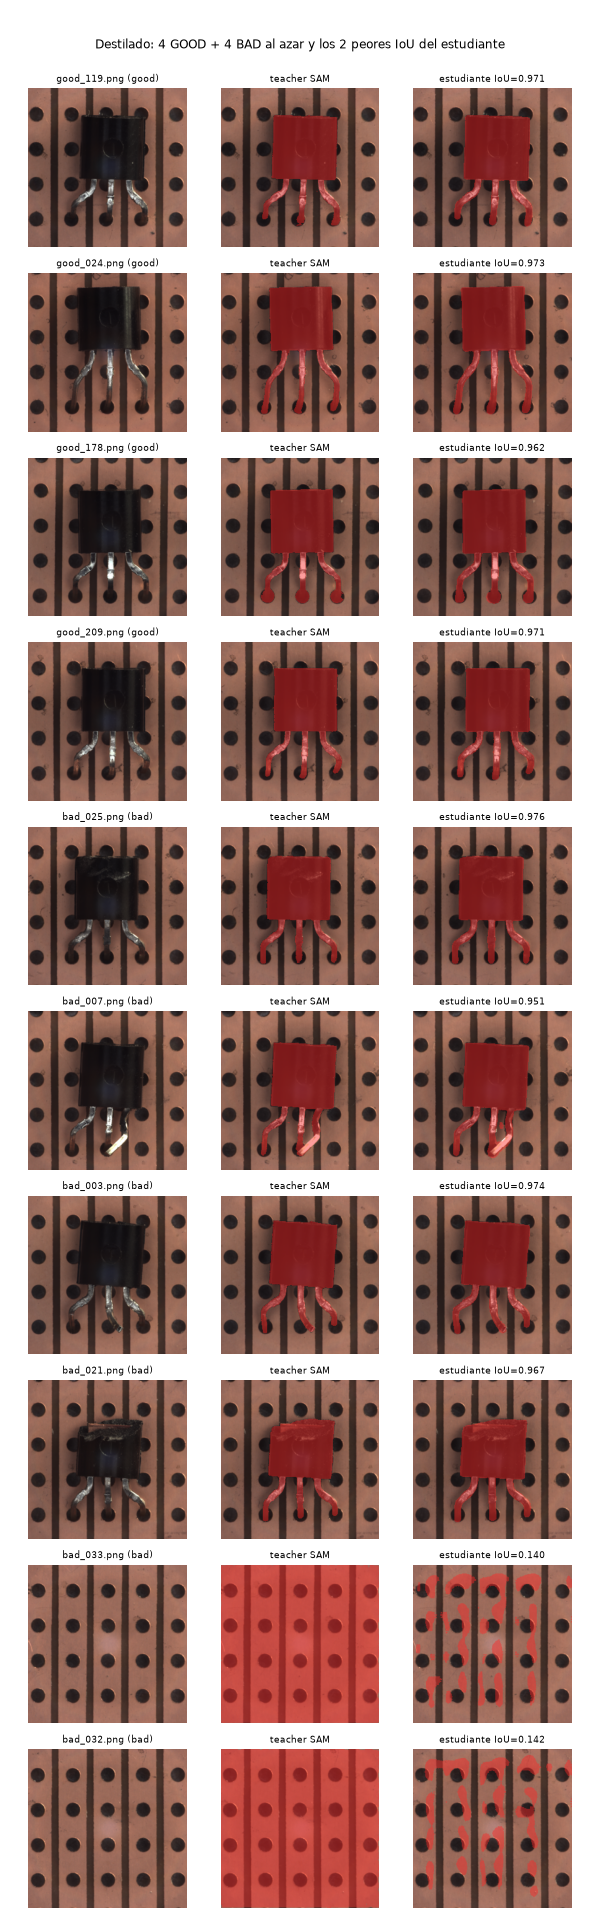

In [ ]:
# §5b Proposito: ejemplos visuales del destilado: original | teacher SAM | estudiante (con IoU contra el teacher).
tic("ejemplos_destilado")
_T = 256
_pos = {f: i for i, f in enumerate(sam_masks.filename)}
_iou = student_quality.set_index("filename").iou
_rng = np.random.default_rng(SEED)
_rows = []
for _lab, _n in (("good", 4), ("bad", 4)):
    _sub = df_files[df_files.label == _lab].reset_index(drop=True)
    _rows += [_sub.iloc[int(_k)] for _k in _rng.choice(len(_sub), size=min(_n, len(_sub)), replace=False)]
_have = {_r.filename for _r in _rows}
for _fn in student_quality.sort_values("iou").filename.head(2):
    if _fn not in _have:
        _rows.append(df_files[df_files.filename == _fn].iloc[0])

def _overlay(_arr, _mask):
    _o = _arr.copy()
    _o[_mask] = (0.55 * _o[_mask] + 0.45 * np.array([255, 40, 40])).astype("uint8")
    return _o

_fig, _ax = plt.subplots(len(_rows), 3, figsize=(7.5, 2.4 * len(_rows)))
_fig.patch.set_facecolor("white")
for _k, _r in enumerate(_rows):
    _arr = np.asarray(Image.open(_r.path).convert("RGB").resize((_T, _T)))
    _tm = np.asarray(Image.open(teacher_mask_dir / _r.filename).resize((_T, _T))) > 127
    _sm = sam_masks256[_pos[_r.filename]].numpy().astype(bool)
    _tit = ["%s (%s)" % (_r.filename, _r.label), "teacher SAM", "estudiante IoU=%.3f" % _iou[_r.filename]]
    for _c, _img in enumerate([_arr, _overlay(_arr, _tm), _overlay(_arr, _sm)]):
        _ax[_k][_c].imshow(_img)
        _ax[_k][_c].set_title(_tit[_c], fontsize=8, color="black")
        _ax[_k][_c].axis("off")
_fig.suptitle("Destilado: 4 GOOD + 4 BAD al azar y los 2 peores IoU del estudiante", fontsize=11, color="black")
_fig.tight_layout(rect=(0, 0, 1, 0.98))
_png = FIG_DIR / "ejemplos_destilado.png"
_fig.savefig(_png, dpi=80)
plt.close(_fig)
print("saved", _png.name, "(%d filas)" % len(_rows))
toc("ejemplos_destilado")
mo.image(str(_png))

### §6 build_masked/variant_image: constructor canonico de imagen (none/crop/masked) + media GOOD-train

In [ ]:
# §6 Proposito: construye cada variante con las mascaras del ESTUDIANTE (sam_masks viene de §5)
# + fondo masked = media de GOOD-train (nunca test).
tic("variants")
_good_tr = train_files[train_files.label == "good"]
_sizes = {}
for _gf in _good_tr.itertuples():
    with Image.open(_gf.path) as _oo:
        _sizes[_oo.size] = _sizes.get(_oo.size, 0) + 1
if len(_sizes) > 1:
    print("AVISO: tamanos heterogeneos en GOOD-train (todo se redimensiona a 1024x1024): " + ", ".join(f"{_w}x{_h}x{_n}" for (_w, _h), _n in sorted(_sizes.items())))
_mean = np.zeros((1024, 1024, 3), np.float64)
for _gf in _good_tr.itertuples():
    _mean += np.asarray(Image.open(_gf.path).convert("RGB").resize((1024, 1024)), np.float64)
good_mean = (_mean / len(_good_tr)).astype("uint8")
print(f"media GOOD-train de {len(_good_tr)} fotos")
_qc = {r.filename: (r.area, r.edge, (r.x0, r.y0, r.x1, r.y1) if r.bbox else None) for r in sam_masks.itertuples()}
_n_fb = []

def build_masked(im_pil, mask_bool):
    # UNICO constructor masked: batch (§6) y produccion (§13) ven la misma imagen.
    _m1024 = np.array(Image.fromarray(np.asarray(mask_bool).astype("uint8") * 255).resize((1024, 1024))) > 0
    return Image.fromarray(np.where(_m1024[:, :, None], np.asarray(im_pil.resize((1024, 1024))), good_mean).astype("uint8"))

def variant_image(filename, path, variant):
    _im = Image.open(path).convert("RGB")
    if variant == "none":
        return _im
    _area, _edge, _bb = _qc[filename]
    if _bb is None or _bb[0] < 0 or _area < MIN_MASK_AREA_RATIO or _area > MAX_MASK_AREA_RATIO or _edge:
        _n_fb.append(filename)
        return _im
    if variant == "crop":
        return _im.crop(expand_bbox(_bb, (_im.size[1], _im.size[0]), SAM_PADDING))
    _mk = np.array(Image.open(MODELS_DIR / "student" / "masks_png" / filename)) > 127
    return build_masked(_im, _mk)

good_mean_npy = MODELS_DIR / "good_mean.npy"
np.save(good_mean_npy, good_mean)
print("saved good_mean.npy", good_mean.shape)
toc("variants")

[15:40:35] inicio variants
media GOOD-train de 218 fotos
saved good_mean.npy (1024, 1024, 3)
[15:40:44] fin variants (9.4s)


### §7 DINO en la variante elegida + LogReg + export ONNX

In [ ]:
# §7 Proposito: embeddings CLS DINOv2 de la variante DINO_VARIANT (cache por fingerprint).
tic("dino_embed")

_ck = MODELS_DIR / f"dino_{DINO_VARIANT}.pt"
_stud_sha = hashlib.sha256(student_ckpt.read_bytes()).hexdigest()[:16]
_gsha = hashlib.sha256(good_mean_npy.read_bytes()).hexdigest()[:16]
_dkey = {"fingerprint": fingerprint, "stud_sha": _stud_sha, "variant": DINO_VARIANT, "backbone": BACKBONE_ID, "preproc": PREPROC_VERSION, "gmean": _gsha}
_dpok = False
if _ck.exists():
    _dpm = torch.load(_ck, map_location="cpu", weights_only=False)
    _dpok = all(_dpm.get(_k) == _v for _k, _v in _dkey.items())
    del _dpm
if _dpok:
    _dp = torch.load(_ck, map_location="cpu", weights_only=False)
    dino_X, dino_fnames = _dp["X"], _dp["fnames"]
    print("dino cache hit:", dino_X.shape, "(ckpt %s)" % _stud_sha)
else:
    _proc = AutoImageProcessor.from_pretrained(BACKBONE_ID)
    _model = AutoModel.from_pretrained(BACKBONE_ID).eval()
    for _pp in _model.parameters():
        _pp.requires_grad_(False)
    _dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    _model.to(_dev)
    _xs, _fn = [], []
    for _k, _r in enumerate(df_files.itertuples()):
        _ci = variant_image(_r.filename, _r.path, DINO_VARIANT)
        _in = _proc(images=_ci, size={"height": 224, "width": 224}, return_tensors="pt")
        with torch.inference_mode():
            _xs.append(_model(**{k: v.to(_dev) for k, v in _in.items()}).last_hidden_state[:, 0, :].cpu())
        _fn.append(_r.filename)
        if (_k + 1) % 50 == 0:
            print(f"dino {_k + 1}/{len(df_files)}", flush=True)
    import numpy as _np

    dino_X, dino_fnames = _np.concatenate([x.numpy() for x in _xs]), _fn
    torch.save({"X": dino_X, "fnames": dino_fnames, **_dkey}, _ck)
    print("saved", dino_X.shape)
toc("dino_embed")
try:
    _model.to("cpu")
    print("DINO descargado")
except NameError:
    print("DINO ya estaba descargado (cache hit)")
import gc as _gc
_gc.collect()
torch.cuda.empty_cache()
print("DINO descargado, VRAM:", round(torch.cuda.memory_allocated() / 1e9, 2), "GB")

[15:40:44] inicio dino_embed
dino cache hit: (313, 768) (ckpt 728aa7f56b5cb1f4)
[15:40:44] fin dino_embed (0.2s)
DINO ya estaba descargado (cache hit)
DINO descargado, VRAM: 0.0 GB


In [ ]:
# §7 Proposito: LogReg en train, metricas en test, scores y export a ONNX con parity check.
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report as _crN, roc_auc_score as _aucN

tic("dino_train")
_y_all = (df_files.set_index("filename").loc[dino_fnames, "label"] == "bad").to_numpy(int)
_pos = {f: i for i, f in enumerate(dino_fnames)}
_tri = [_pos[f] for f in train_files.filename]
_tei = [_pos[f] for f in test_files.filename]
_clf = LogisticRegression(class_weight="balanced", C=1.0, max_iter=2000).fit(dino_X[_tri], _y_all[_tri])
dino_scores = _clf.predict_proba(dino_X)[:, 1]
_cut = float(np.quantile(dino_scores[_tri][_y_all[_tri] == 0], 0.95))
_pr = (dino_scores[_tei] >= _cut).astype(int)
_yte = _y_all[_tei]
print(_crN(_yte, _pr, target_names=["good", "bad"], zero_division=0))
print(f"dino-test: auroc={_aucN(_yte, dino_scores[_tei]):.4f} cut={_cut:.3f}")
dino_npz = MODELS_DIR / "dino.npz"
np.savez(dino_npz, fnames=np.array(dino_fnames), y=_y_all, scores=dino_scores,
         train_idx=np.array(_tri), test_idx=np.array(_tei), cut=_cut)
from skl2onnx import to_onnx
from skl2onnx.common.data_types import FloatTensorType
import onnxruntime as _ort7

_onnx = to_onnx(_clf, initial_types=[("input", FloatTensorType([None, dino_X.shape[1]]))], options={"zipmap": False})
(MODELS_DIR / "dino_logreg.onnx").write_bytes(_onnx.SerializeToString())
_sess7 = _ort7.InferenceSession(str(MODELS_DIR / "dino_logreg.onnx"))
_onnx_scores = _sess7.run(None, {"input": dino_X.astype("float32")})[1][:, 1]
_maxdiff = float(np.abs(_onnx_scores - dino_scores).max())
assert _maxdiff < 1e-5, f"ONNX LogReg diverge del sklearn original: maxdiff={_maxdiff}"
print("saved dino.npz + dino_logreg.onnx (parity maxdiff=%.2e)" % _maxdiff)
toc("dino_train")

[15:40:45] inicio dino_train
              precision    recall  f1-score   support

        good       1.00      0.93      0.96        55
         bad       0.67      1.00      0.80         8

    accuracy                           0.94        63
   macro avg       0.83      0.96      0.88        63
weighted avg       0.96      0.94      0.94        63

dino-test: auroc=0.9886 cut=0.056
saved dino.npz + dino_logreg.onnx (parity maxdiff=8.34e-07)
[15:40:45] fin dino_train (0.4s)


### §7b DINO por vecinos: por qué decide BAD
Para cada BAD de test (y 2 GOOD de contraste): lo que DINO ve (variante masked) y sus 3 vecinos más cercanos en **train** por distancia coseno.
Si una pieza BAD cae cerca de BAD de train, DINO la marca con apoyo; si cae entre GOOD, es un caso límite.

[15:40:45] inicio explain_dino
saved explain_dino.png | BAD de test con >=2 vecinos BAD en train: 2/6
[15:40:47] fin explain_dino (2.1s)



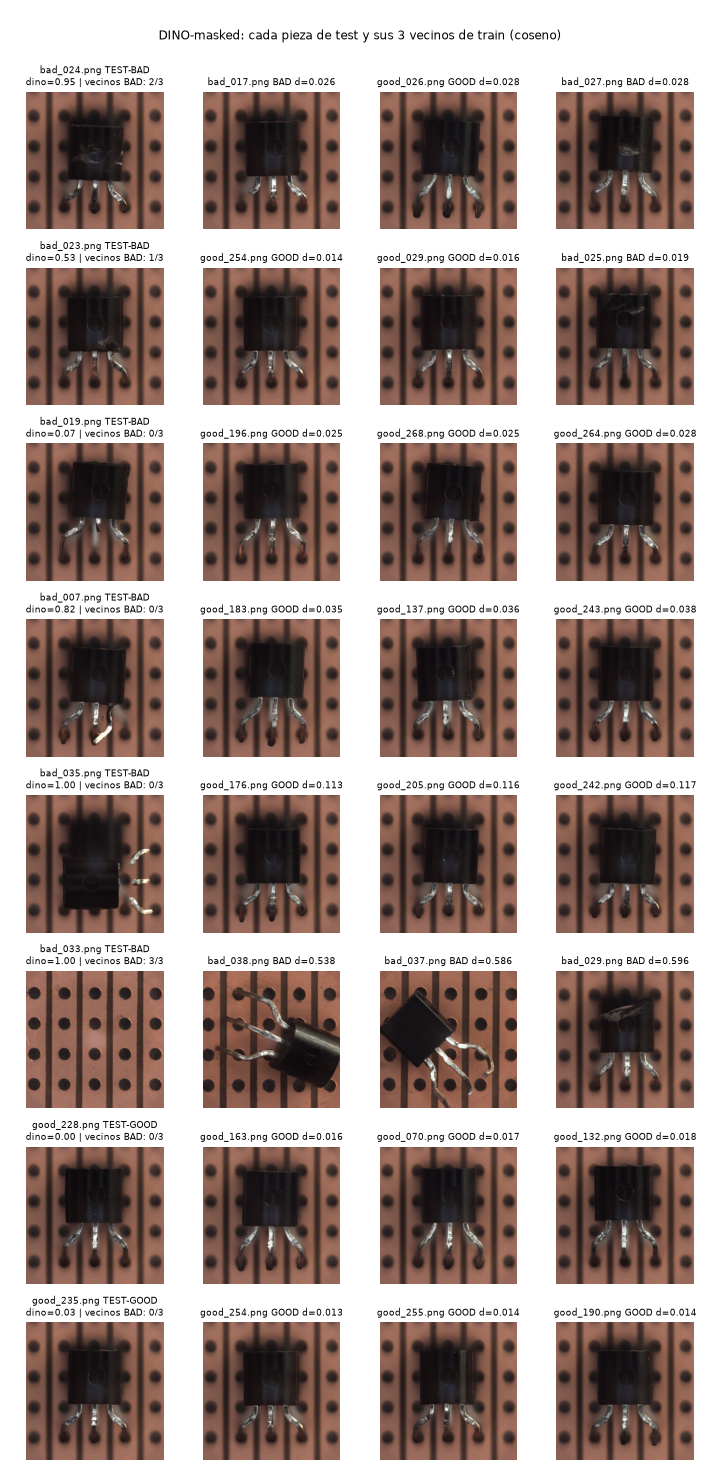

In [ ]:
# §7b Proposito: explicar a DINO por vecinos: BAD (y 2 GOOD) de test y sus 3 trains mas cercanos (coseno).
tic("explain_dino")
_pos = {f: i for i, f in enumerate(dino_fnames)}
_pathof = dict(zip(df_files.filename, df_files.path))
_labof = dict(zip(df_files.filename, df_files.label))
_tr = np.array([_pos[f] for f in train_files.filename])
_Xn = dino_X / np.linalg.norm(dino_X, axis=1, keepdims=True)
_qs = list(test_files[test_files.label == "bad"].filename.head(6)) + list(test_files[test_files.label == "good"].filename.head(2))
_T = 224
_fig, _ax = plt.subplots(len(_qs), 4, figsize=(9, 2.3 * len(_qs)))
_fig.patch.set_facecolor("white")
_bad_support = []
for _k, _fn in enumerate(_qs):
    _i = _pos[_fn]
    _sim = _Xn[_tr] @ _Xn[_i]
    _top = _tr[np.argsort(-_sim)[:3]]
    _nb_bad = int(sum(_labof[dino_fnames[_j]] == "bad" for _j in _top))
    if _labof[_fn] == "bad":
        _bad_support.append(_nb_bad)
    _ax[_k][0].imshow(variant_image(_fn, _pathof[_fn], DINO_VARIANT).resize((_T, _T)))
    _ax[_k][0].set_title("%s TEST-%s\ndino=%.2f | vecinos BAD: %d/3" % (_fn, _labof[_fn].upper(), dino_scores[_i], _nb_bad), fontsize=8, color="black")
    for _c, _j in enumerate(_top):
        _nf = dino_fnames[_j]
        _ax[_k][_c + 1].imshow(variant_image(_nf, _pathof[_nf], DINO_VARIANT).resize((_T, _T)))
        _ax[_k][_c + 1].set_title("%s %s d=%.3f" % (_nf, _labof[_nf].upper(), 1 - float(_Xn[_j] @ _Xn[_i])), fontsize=8, color="black")
    [_a.axis("off") for _a in _ax[_k]]
_fig.suptitle("DINO-%s: cada pieza de test y sus 3 vecinos de train (coseno)" % DINO_VARIANT, fontsize=11, color="black")
_fig.tight_layout(rect=(0, 0, 1, 0.98))
_png = FIG_DIR / "explain_dino.png"
_fig.savefig(_png, dpi=80)
plt.close(_fig)
print("saved", _png.name, "| BAD de test con >=2 vecinos BAD en train: %d/%d" % (sum(_s >= 2 for _s in _bad_support), len(_bad_support)))
toc("explain_dino")
mo.image(str(_png))

### §8 EfficientAd en original, STEPS steps con logs + export ONNX

In [ ]:
# §8 Proposito: entrena EfficientAD solo en GOOD-train (variante EFFAD_VARIANT) y exporta a ONNX.
import glob
import os

tic("effad_train")
from lightning.pytorch import seed_everything
from torch.utils.data import DataLoader
from lightning.pytorch import LightningDataModule
from anomalib.data.dataclasses.torch import ImageBatch
from anomalib.models import EfficientAd
from anomalib.engine import Engine

seed_everything(SEED)
_good_tr = train_files[train_files.label == "good"]

def _tensor(_path, _fn):
    _im = variant_image(_fn, _path, EFFAD_VARIANT).resize((256, 256))
    return torch.from_numpy(np.asarray(_im, dtype="float32") / 255.0).permute(2, 0, 1)

class _DM(LightningDataModule):
    def __init__(self, _t):
        super().__init__()
        self.train_batch_size = 1
        self.name = EFFAD_VARIANT
        self.category = EFFAD_VARIANT
        self._t = _t

    def train_dataloader(self):
        return DataLoader(self._t, batch_size=1, shuffle=True, collate_fn=lambda _b: ImageBatch(image=torch.stack(_b)))

from lightning.pytorch.callbacks import Callback as _CB
class _LogSteps(_CB):
    def on_train_batch_end(self, trainer, *_a, **_k):
        _gs = int(trainer.global_step)
        if _gs % 250 == 0 and _gs > 0:
            _mm = {k: float(v) for k, v in trainer.callback_metrics.items()}
            _msg = " ".join(k + "=" + format(v, ".4f") for k, v in _mm.items()) or "(sin metricas)"
            print("effad step %d/%d %s" % (_gs, STEPS, _msg), flush=True)
_model = EfficientAd(model_size=EFFAD_SIZE, visualizer=False, evaluator=False)
_eng = Engine(logger=True, default_root_dir=str(MODELS_DIR / "effad"), max_steps=STEPS, callbacks=[_LogSteps()])
print(f"entrenando EffAD-{EFFAD_SIZE} en {len(_good_tr)} GOOD x {STEPS} steps (log cada N steps en light_logs/)", flush=True)
import glob as _gb2
import time as _tg
# El ckpt solo se reutiliza si dataset, split y receta coinciden: si no, se aparta (no se borra) y se entrena de cero.
_stamp = "%s|%s|%s|%s|%s" % (fingerprint, TEST_SIZE, SEED, EFFAD_SIZE, STEPS)
_stamp_file = MODELS_DIR / "effad" / "fingerprint.txt"
if (MODELS_DIR / "effad").exists() and (not _stamp_file.exists() or _stamp_file.read_text().strip() != _stamp):
    _old = MODELS_DIR / ("effad_stale_" + _tg.strftime("%Y%m%dT%H%M%S"))
    (MODELS_DIR / "effad").rename(_old)
    print("EffAD previo no coincide con este dataset/receta: movido a", _old.name, "y se entrena desde cero", flush=True)
_ckpts = sorted(_gb2.glob(str(MODELS_DIR / "effad/**/*.ckpt"), recursive=True), key=os.path.getmtime)
_resume = _ckpts[-1] if _ckpts else None
print("resume desde:", _resume, flush=True)
_eng.fit(model=_model, datamodule=_DM([_tensor(r.path, r.filename) for r in _good_tr.itertuples()]), ckpt_path=_resume)
(MODELS_DIR / "effad").mkdir(parents=True, exist_ok=True)
_stamp_file.write_text(_stamp)
_ckpt = sorted(glob.glob(str(MODELS_DIR / "effad/**/*.ckpt"), recursive=True), key=os.path.getmtime)[-1]
print("ckpt:", _ckpt)

import torch.nn as _nn

class _EffWrap(_nn.Module):
    def __init__(self, _m):
        super().__init__()
        self._m = _m

    def forward(self, _x):
        return self._m(_x).pred_score

_model.eval()
_dummy = torch.zeros(1, 3, 256, 256)
torch.onnx.export(_EffWrap(_model).eval(), _dummy, str(MODELS_DIR / "effad.onnx"),
                  input_names=["input"], output_names=["score"], opset_version=17, dynamo=False)
import onnxruntime as _ort8
_sess8 = _ort8.InferenceSession(str(MODELS_DIR / "effad.onnx"))
with torch.inference_mode():
    _ref8 = float(_EffWrap(_model).eval()(_dummy))
_onnx8 = float(_sess8.run(None, {"input": _dummy.numpy()})[0].flatten()[0])
_maxdiff8 = abs(_ref8 - _onnx8)
assert _maxdiff8 < 1e-5, f"ONNX EffAD diverge del checkpoint: maxdiff={_maxdiff8}"
print("saved effad.onnx (parity maxdiff=%.2e)" % _maxdiff8)
del _model, _eng
import gc as _gcE
_gcE.collect()
torch.cuda.empty_cache()
toc("effad_train")

[15:40:47] inicio effad_train


W1117 15:40:48.089000 39180 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels
C:\Users\user\Documents\qc-vision-inspector\.venv\Lib\site-packages\anomalib\models\image\dinomaly\components\layers.py:22: FutureWarning: The anomalib.models.components.dinov2 package is deprecated and will be removed in a future release. Please use the timm-based feature extractor instead: anomalib.models.components.feature_extractors.TimmFeatureExtractor
  from anomalib.models.components.dinov2.layers import Attention, DropPath, LayerScale, MemEffAttention
2026/11/17 15:40:50 INFO mlflow.agent.hint: Load the `mlflow-trace-instrumentation` skill at C:\Users\user\Documents\qc-vision-inspector\.venv\Lib\site-packages\mlflow\assistant\skills\mlflow-trace-instrumentation\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.
Seed set to 42


entrenando EffAD-medium en 218 GOOD x 5000 steps (log cada N steps en light_logs/)
resume desde: models\transistor_binary\industrial_master_v2\effad\EfficientAd\none\none\v0\weights\lightning\model.ckpt


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
C:\Users\user\Documents\qc-vision-inspector\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\logger_connector\logger_connector.py:76: Starting from v1.9.0, `tensorboardX` has been removed as a dependency of the `lightning.pytorch` package, due to potential conflicts with other packages in the ML ecosystem. For this reason, `logger=True` will use `CSVLogger` as the default logger, unless the `tensorboard` or `tensorboardX` packages are found. Please `pip install lightning[extra]` or one of them to enable TensorBoard support by default
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
C:\Users\user\Documents\qc-vision-inspector\.venv\Lib\site-packages\lightning\pytorch\trainer\configuration_validator.py:70: You defined a

+----------------------------------------------------------------+
|   | Name           | Type             | Params | Mode  | FLOPs |
|---+----------------+------------------+--------+-------+-------|
| 0 | pre_processor  | PreProcessor     |      0 | train |     0 |
| 1 | post_processor | PostProcessor    |      0 | train |     0 |
| 2 | model          | EfficientAdModel | 20.7 M | train |     0 |
+----------------------------------------------------------------+
Trainable params: 20.7 M                                                       
Non-trainable params: 0                                                        
Total params: 20.7 M                                                           
Total estimated model params size (MB): 82.957                                 
Modules in train mode: 43                                                      
Modules in eval mode: 9                                                        
Total FLOPs: 0                                     

Restored all states from the checkpoint at C:\Users\user\Documents\qc-vision-inspector\models\transistor_binary\industrial_master_v2\effad\EfficientAd\none\none\v0\weights\lightning\model.ckpt
C:\Users\user\Documents\qc-vision-inspector\.venv\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
C:\Users\user\Documents\qc-vision-inspector\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.
`Trainer.fit` stopped: `max_steps=5000` reached.


ckpt: models\transistor_binary\industrial_master_v2\effad\EfficientAd\none\none\v0\weights\lightning\model.ckpt


C:\Users\user\AppData\Local\Temp\marimo_39180\__marimo__cell_AjVT_.py:72: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(_EffWrap(_model).eval(), _dummy, str(MODELS_DIR / "effad.onnx"),
C:\Users\user\Documents\qc-vision-inspector\.venv\Lib\site-packages\torch\onnx\_internal\torchscript_exporter\jit_utils.py:308: UserWarning: Constant folding - Only steps=1 can be constant folded for opset >= 10 onnx::Slice op. Constant folding not applied. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\jit\passes\onnx\constant_fold.cpp:180.)
  _C._jit_pass_onnx_node_shape_type_inference(node, params_dict, opset_version)

saved effad.onnx (parity maxdiff=4.77e-07)
[15:41:03] fin effad_train (15.9s)


### §9 Fusion dino + effad (alpha en train) y scores test

In [ ]:
# §9 Proposito: normaliza con train-GOOD, elige alpha en train, corta q95 y scorea test (dino+effad+fusion).
tic("fusion")

_y = (df_files.set_index("filename").loc[dino_fnames, "label"] == "bad").to_numpy(int)
_pos = {f: i for i, f in enumerate(dino_fnames)}
_tri = [_pos[f] for f in train_files.filename]
_tei = [_pos[f] for f in test_files.filename]
_ckpt = sorted(glob.glob(str(MODELS_DIR / "effad/**/*.ckpt"), recursive=True), key=os.path.getmtime)[-1]
_em = EfficientAd.load_from_checkpoint(_ckpt, map_location="cpu").eval()
_dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
_em.to(_dev)
_es = []
with torch.inference_mode():
    for _s in range(0, len(dino_fnames), 16):
        _xb = torch.stack([torch.from_numpy(np.asarray(variant_image(f, df_files.set_index("filename").loc[f, "path"], "none").resize((256, 256)), dtype="float32") / 255.0).permute(2, 0, 1) for f in dino_fnames[_s:_s + 16]]).to(_dev)
        _es.extend(_em(_xb).pred_score.flatten().cpu().tolist())
        if (_s // 16 + 1) % 5 == 0:
            print(f"effad score {_s + 16}/{len(dino_fnames)}", flush=True)
effad_scores = np.array(_es)
_gd = [i for i in _tri if _y[i] == 0]
_md = float(np.median(dino_scores[_gd]))
_id = float(max(np.subtract(*np.percentile(dino_scores[_gd], [75, 25])), 1e-9))
_me = float(np.median(effad_scores[_gd]))
_ie = float(max(np.subtract(*np.percentile(effad_scores[_gd], [75, 25])), 1e-9))
_dtr, _etr = (dino_scores[_tri] - _md) / _id, (effad_scores[_tri] - _me) / _ie
_best = None
for _a in np.arange(0, 1.05, 0.05).round(2):
    _ftr = _a * _dtr + (1 - _a) * _etr
    _thr = float(np.quantile(_ftr[_y[_tri] == 0], 0.95))
    _pr = (_ftr >= _thr).astype(int)
    _rec = float((_pr[_y[_tri] == 1] == 1).mean())
    _far = float((_pr[_y[_tri] == 0] == 1).mean())
    if _best is None or (_rec, -_far) > (_best[1], -_best[2]):
        _best = (float(_a), _rec, _far, _thr)
_alpha, _, _, _cut = _best
fused_scores = _alpha * (dino_scores - _md) / _id + (1 - _alpha) * (effad_scores - _me) / _ie
fusion_npz = MODELS_DIR / "fusion.npz"
np.savez(fusion_npz, alpha=_alpha, cut=_cut, md=_md, id=_id, me=_me, ie=_ie,
         fnames=np.array(dino_fnames), y=_y, dino=dino_scores, effad=effad_scores, fused=fused_scores,
         train_idx=np.array(_tri), test_idx=np.array(_tei))
print(f"alpha={_alpha} cut={_cut:.3f} saved fusion.npz")
_em.to("cpu"); torch.cuda.empty_cache()
print("EffAD descargado")
toc("fusion")

[15:41:03] inicio fusion
effad score 80/313
effad score 160/313
effad score 240/313
effad score 320/313
alpha=0.05 cut=2.162 saved fusion.npz
EffAD descargado
[15:41:18] fin fusion (15.1s)


### §10 Calibracion OOF: alpha/corte de produccion vienen de aqui (no in-sample)

In [ ]:
# §10 Proposito: calibracion fuera de muestra (alpha/corte con scores OOF de train; EffAD fijo por coste).
# Corre ANTES de §12/§13 (a diferencia del notebook fuente) para que infer() nazca ya prefiriendo OOF.
tic("calib_oof")
from sklearn.linear_model import LogisticRegression as _LRC
_fzc = np.load(fusion_npz)
_yc = _fzc["y"].astype(int)
_trc = list(_fzc["train_idx"])
_Xtr = dino_X[_trc]; _ytr = _yc[_trc]
_groups_tr = df_files.iloc[_trc][group_col].to_numpy() if group_col is not None else None
_folds = cv_splits(_ytr, groups=_groups_tr)
_oof = np.zeros(len(_trc))
for _tr, _va in _folds:
    _clc = _LRC(class_weight="balanced", C=1.0, max_iter=2000).fit(_Xtr[_tr], _ytr[_tr])
    _oof[_va] = _clc.predict_proba(_Xtr[_va])[:, 1]
_gd = [i for i in range(len(_trc)) if _ytr[i] == 0]
_mdc = float(np.median(_oof[_gd])); _idc = float(max(np.subtract(*np.percentile(_oof[_gd], [75, 25])), 1e-9))
_esc = effad_scores[_trc]
_mec = float(np.median(_esc[_gd])); _iec = float(max(np.subtract(*np.percentile(_esc[_gd], [75, 25])), 1e-9))
_doo = (_oof - _mdc) / _idc; _eoo = (_esc - _mec) / _iec
_bst = None
for _ac in np.arange(0, 1.05, 0.05).round(2):
    _fc = _ac * _doo + (1 - _ac) * _eoo
    _hc = float(np.quantile(_fc[_gd], 0.95))
    _pc = (_fc >= _hc).astype(int)
    _rc = float((_pc[_ytr == 1] == 1).mean()); _fc_ = float((_pc[_ytr == 0] == 1).mean())
    if _bst is None or (_rc, -_fc_) > (_bst[1], -_bst[2]):
        _bst = (float(_ac), _rc, _fc_, _hc)
print("OOF train (%d folds): alpha=%.2f recall=%.3f far=%.3f cut=%.3f" % (len(_folds), *_bst), flush=True)
print("in-sample §9: alpha=%.2f cut=%.3f" % (float(_fzc["alpha"]), float(_fzc["cut"])), flush=True)
calib_oof_npz = MODELS_DIR / "calib_oof.npz"
np.savez(calib_oof_npz, oof=_oof, alpha=_bst[0], rec=_bst[1], far=_bst[2], cut=_bst[3], train_idx=np.array(_trc))
print("saved calib_oof.npz (EffAD fijo: reentrenarlo por fold es inviable)")
_fz5 = dict(np.load(fusion_npz))
_fz5.update({"oof_alpha": _bst[0], "oof_cut": _bst[3], "oof_md": _mdc, "oof_id": _idc, "oof_me": _mec, "oof_ie": _iec})
np.savez(fusion_npz, **_fz5)
print("fusion.npz: calibracion OOF integrada (infer la prefiere, in-sample queda de fallback)")
toc("calib_oof")

[15:41:18] inicio calib_oof
OOF train (3 folds): alpha=0.20 recall=1.000 far=0.050 cut=2.641
in-sample §9: alpha=0.05 cut=2.162
saved calib_oof.npz (EffAD fijo: reentrenarlo por fold es inviable)
fusion.npz: calibracion OOF integrada (infer la prefiere, in-sample queda de fallback)
[15:41:18] fin calib_oof (0.1s)


### §11 Evaluacion: reportes, matrices, bootstrap IC95, McNemar + figuras

[15:41:18] inicio eval
dino {'method': 'dino', 'auroc': 0.9886, 'recall': 1.0, 'far': 0.073, 'prec_bad': 0.667, 'f1_bad': 0.8}
effad {'method': 'effad', 'auroc': 0.9795, 'recall': 0.875, 'far': 0.127, 'prec_bad': 0.5, 'f1_bad': 0.636}
fused {'method': 'fused', 'auroc': 0.9886, 'recall': 1.0, 'far': 0.127, 'prec_bad': 0.533, 'f1_bad': 0.696}
bootstrap 200/200 (test n=63): fused recall IC95 [1.000, 1.000] FAR IC95 [0.036, 0.207]
recall fusion 8/8: IC95 binomial [0.631, 1.000] n=8
McNemar: {('dino', 'effad'): 0.2188, ('dino', 'fused'): 0.375, ('effad', 'fused'): 1.0}
saved eval.csv, recall.png, cm.png
[15:41:19] fin eval (1.0s)



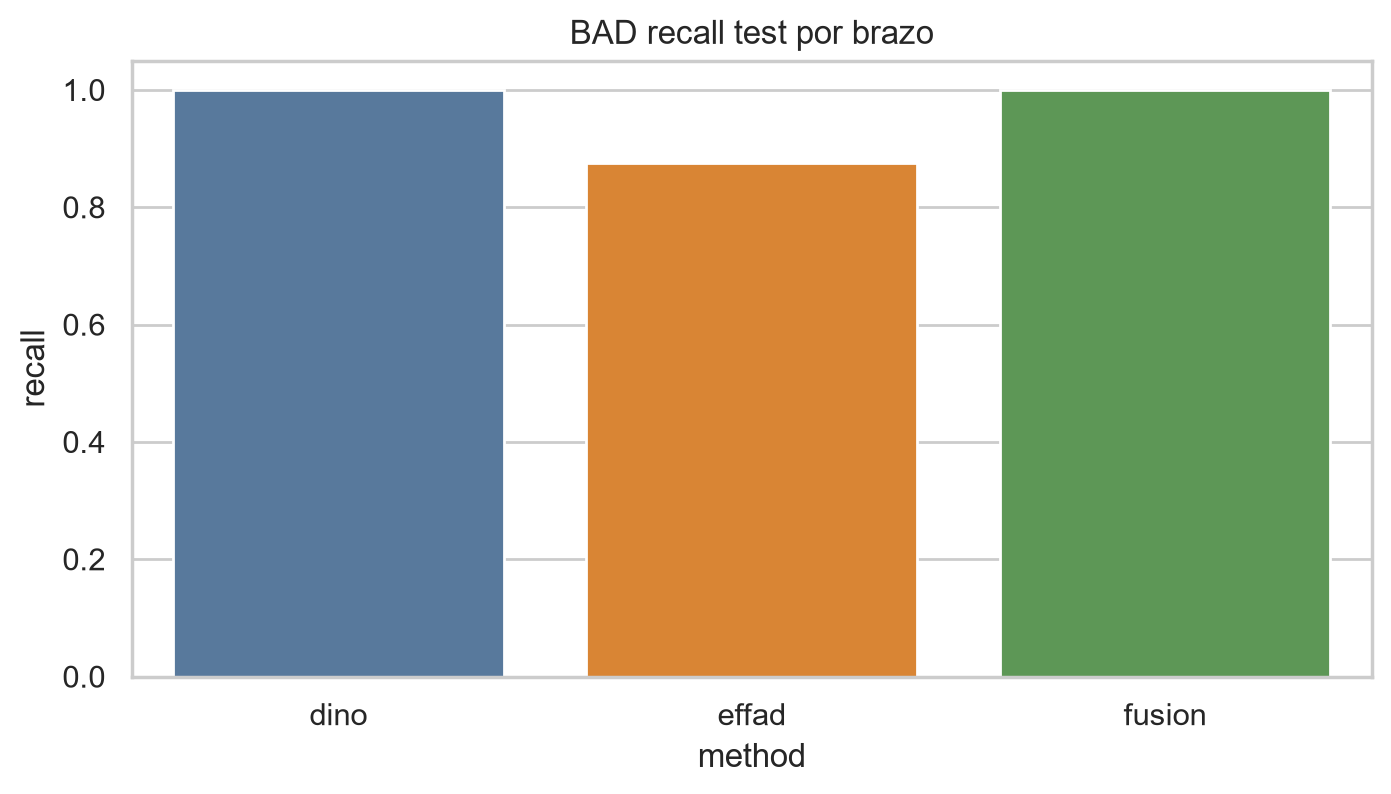
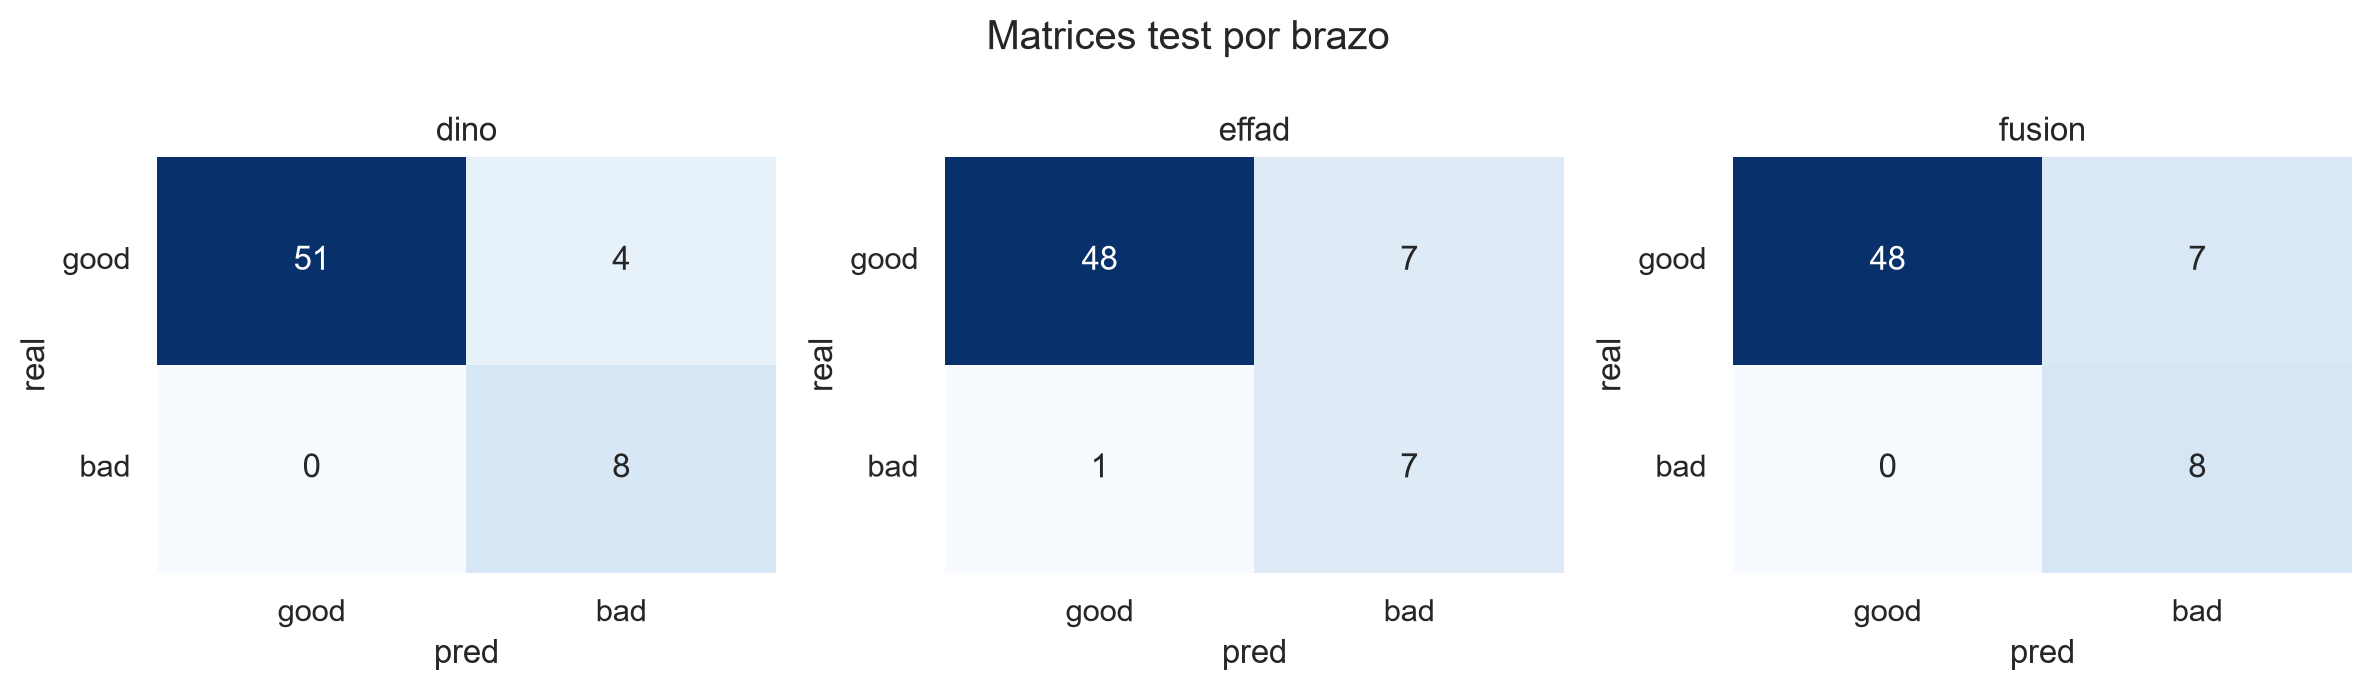

In [ ]:
# §11 Proposito: metricas test por brazo + figuras seaborn (barras + matrices + McNemar). Sin hardcodes.
tic("eval")
import seaborn as sns
from sklearn.metrics import classification_report as _cr6, confusion_matrix as _cmx6, roc_auc_score as _auc6
sns.set_theme(style="whitegrid")
_fz = np.load(fusion_npz)
_y = _fz["y"].astype(int)
_te = _fz["test_idx"]
_yte = _y[_te]
_pal = {"dino": "#4C78A8", "effad": "#F58518", "fusion": "#54A24B"}
_rows, _preds = [], {}
for _m in ("dino", "effad", "fused"):
    _sc = _fz[{"dino": "dino", "effad": "effad", "fused": "fused"}[_m]]
    _cut = float(np.quantile(_sc[_fz["train_idx"]][_y[_fz["train_idx"]] == 0], 0.95))
    _pr = (_sc[_te] >= _cut).astype(int)
    _preds[_m] = _pr
    _rep = _cr6(_yte, _pr, target_names=["good", "bad"], output_dict=True, zero_division=0)
    _rows.append({"method": _m, "auroc": round(float(_auc6(_yte, _sc[_te])), 4), "recall": round(float(_rep["bad"]["recall"]), 3), "far": round(float((_pr[_yte == 0] == 1).mean()), 3), "prec_bad": round(float(_rep["bad"]["precision"]), 3), "f1_bad": round(float(_rep["bad"]["f1-score"]), 3)})
    print(_m, _rows[-1], flush=True)
eval_df = pd.DataFrame(_rows)
eval_df.to_csv(MODELS_DIR / "eval.csv", index=False)
_rng6 = np.random.default_rng(SEED)
_nb6 = []
_S6 = {"dino": "dino", "effad": "effad", "fused": "fused"}
for _b6 in range(N_BOOT):
    _ib = _rng6.integers(0, len(_te), len(_te))
    _yb = _yte[_ib]
    if _yb.min() == _yb.max():
        continue
    _rb = {"boot": _b6}
    for _m in ("dino", "effad", "fused"):
        _sb = _fz[_S6[_m]][_te][_ib]
        _cb = float(np.quantile(_fz[_S6[_m]][_fz["train_idx"]][_y[_fz["train_idx"]] == 0], 0.95))
        _pb = (_sb >= _cb).astype(int)
        _rb[_m + "_auroc"] = round(float(_auc6(_yb, _sb)), 4)
        _rb[_m + "_recall"] = round(float((_pb[_yb == 1] == 1).mean()), 3)
        _rb[_m + "_far"] = round(float((_pb[_yb == 0] == 1).mean()), 3)
    _nb6.append(_rb)
_boot6 = pd.DataFrame(_nb6)
eval_bootstrap_csv = MODELS_DIR / "eval_bootstrap.csv"
_boot6.to_csv(eval_bootstrap_csv, index=False)
_qb = _boot6.quantile([0.025, 0.975])
print("bootstrap %d/%d (test n=%d): fused recall IC95 [%.3f, %.3f] FAR IC95 [%.3f, %.3f]" % (
    len(_boot6), N_BOOT, len(_te), _qb.loc[0.025, "fused_recall"], _qb.loc[0.975, "fused_recall"], _qb.loc[0.025, "fused_far"], _qb.loc[0.975, "fused_far"]))
_nbad = int((_yte == 1).sum()); _hbad = int((_preds["fused"][_yte == 1] == 1).sum())
import math as _mcp
if _hbad == _nbad:
    _cpi = (0.025 ** (1.0 / _nbad), 1.0)
else:
    _ph = _hbad / _nbad; _zz = 1.96
    _ct = (_ph + _zz * _zz / (2 * _nbad)) / (1 + _zz * _zz / _nbad)
    _hw = _zz * _mcp.sqrt(_ph * (1 - _ph) / _nbad + _zz * _zz / (4 * _nbad * _nbad)) / (1 + _zz * _zz / _nbad)
    _cpi = (max(0.0, _ct - _hw), min(1.0, _ct + _hw))
print("recall fusion %d/%d: IC95 binomial [%.3f, %.3f] n=%d" % (_hbad, _nbad, _cpi[0], _cpi[1], _nbad), flush=True)
_mlab = ["dino", "effad", "fusion"]

def mcnemar_hitmiss(pred_a, pred_b, y_true):
    # McNemar sobre acierto/error vs etiqueta real (no sobre acuerdo de predicciones crudas).
    import math as _m6
    _caa, _cbb = (pred_a == y_true), (pred_b == y_true)
    _n01 = int(((_caa == 0) & (_cbb == 1)).sum())
    _n10 = int(((_caa == 1) & (_cbb == 0)).sum())
    _n = _n01 + _n10
    return 1.0 if _n == 0 else round(min(1.0, 2.0 * sum(_m6.comb(_n, _k) for _k in range(0, min(_n01, _n10) + 1)) / 2.0 ** _n), 4)
mcnemar_results = {p: mcnemar_hitmiss(_preds[p[0]], _preds[p[1]], _yte) for p in [("dino", "effad"), ("dino", "fused"), ("effad", "fused")]}
print("McNemar:", mcnemar_results, flush=True)
_fe, _ae = plt.subplots(figsize=(8, 4))
sns.barplot(data=pd.DataFrame({"method": _mlab, "recall": [r["recall"] for r in _rows]}), x="method", y="recall", hue="method", legend=False, palette=_pal, ax=_ae, order=_mlab)
_ae.set(title="BAD recall test por brazo", ylim=(0, 1.05))
_fm, _am = plt.subplots(1, 3, figsize=(12, 3.5))
for _ax, _m in zip(_am, _mlab):
    _tn, _fp, _fn, _tp = _cmx6(_yte, _preds[{"dino": "dino", "effad": "effad", "fusion": "fused"}[_m]]).ravel()
    sns.heatmap([[_tn, _fp], [_fn, _tp]], annot=True, fmt="d", cmap="Blues", cbar=False, ax=_ax)
    _ax.set(title=_m, xlabel="pred", ylabel="real")
    _ax.set_xticklabels(["good", "bad"])
    _ax.set_yticklabels(["good", "bad"], rotation=0)
_fm.suptitle("Matrices test por brazo")
_fm.tight_layout()
FIG_DIR.mkdir(parents=True, exist_ok=True)
_fe.savefig(FIG_DIR / "recall.png", dpi=100)
_fm.savefig(FIG_DIR / "cm.png", dpi=100)
print("saved eval.csv, recall.png, cm.png")
toc("eval")
mo.vstack([_fe, _fm])

### §11b Mini reporte: piezas de test mal clasificadas por la fusión de producción
Usa el brazo `prod` de §11 (calibración OOF y su corte, lo que decide `infer()`). Para cada error: scores de DINO y EffAD,
cuánto empuja cada brazo hacia BAD (aporte = su término de la fusión) y dónde mira EffAD. Es solo diagnóstico: no recalibra nada.

[15:41:19] inicio errores_prod
saved errores_fusion_prod.png
[15:41:21] fin errores_prod (1.5s)


Resultado en test 
 
 55 GOOD + 8 BAD, corte prod = 2.641 (alpha OOF = 0.20). 
 6 falsas alarmas (FP) de 55 GOOD y 0 BAD perdidas (FN) de 8 BAD. 
 En los FP el brazo que mas empuja hacia BAD es EffAD en 3 y DINO en 3. Margen medio sobre el corte: 2.57. 
 <marimo-table data-initial-value='[]' data-label='null' data-data='"[{\"filename\":\"good_130.png\",\"real\":\"GOOD\",\"error\":\"FP (falsa alarma)\",\"dino\":0.004,\"effad\":0.49,\"aporte_dino\":0.01,\"aporte_effad\":3.18,\"fusion\":3.19,\"corte\":2.641,\"margen\":0.55,\"area_mascara\":0.195},{\"filename\":\"good_203.png\",\"real\":\"GOOD\",\"error\":\"FP (falsa alarma)\",\"dino\":0.256,\"effad\":0.386,\"aporte_dino\":2.53,\"aporte_effad\":2.0,\"fusion\":4.53,\"corte\":2.641,\"margen\":1.89,\"area_mascara\":0.191},{\"filename\":\"good_149.png\",\"real\":\"GOOD\",\"error\":\"FP (falsa alarma)\",\"dino\":0.007,\"effad\":0.527,\"aporte_dino\":0.04,\"aporte_effad\":3.6,\"fusion\":3.64,\"corte\":2.641,\"margen\":1.0,\"area_mascara\":0.206},{\"filename\":\"good_272.png\",\"real\":\"GOOD\",\"error\":\"FP (falsa alarma)\",\"dino\":0.312,\"effad\":0.393,\"aporte_dino\":3.09,\"aporte_effad\":2.08,\"fusion\":5.18,\"corte\":2.641,\"margen\":2.54,\"area_mascara\":0.191},{\"filename\":\"good_257.png\",\"real\":\"GOOD\",\"error\":\"FP (falsa alarma)\",\"dino\":0.901,\"effad\":0.396,\"aporte_dino\":8.98,\"aporte_effad\":2.11,\"fusion\":11.09,\"corte\":2.641,\"margen\":8.45,\"area_mascara\":0.193},{\"filename\":\"good_241.png\",\"real\":\"GOOD\",\"error\":\"FP (falsa alarma)\",\"dino\":0.029,\"effad\":0.506,\"aporte_dino\":0.26,\"aporte_effad\":3.36,\"fusion\":3.62,\"corte\":2.641,\"margen\":0.98,\"area_mascara\":0.196}]"' data-total-rows='6' data-total-columns='11' data-max-columns='50' data-banner-text='""' data-pagination='false' data-page-size='6' data-field-types='[["filename",["string","str"]],["real",["string","str"]],["error",["string","str"]],["dino",["number","float64"]],["effad",["number","float64"]],["aporte_dino",["number","float64"]],["aporte_effad",["number","float64"]],["fusion",["number","float64"]],["corte",["number","float64"]],["margen",["number","float64"]],["area_mascara",["number","float64"]]]' data-show-filters='true' data-show-download='true' data-show-search='true' data-show-column-summaries='false' data-show-data-types='true' data-show-page-size-selector='true' data-show-column-explorer='true' data-show-chart-builder='true' data-row-headers='[]' data-hidden-columns='[]' data-has-stable-row-id='false' data-lazy='false' data-preload='false'>
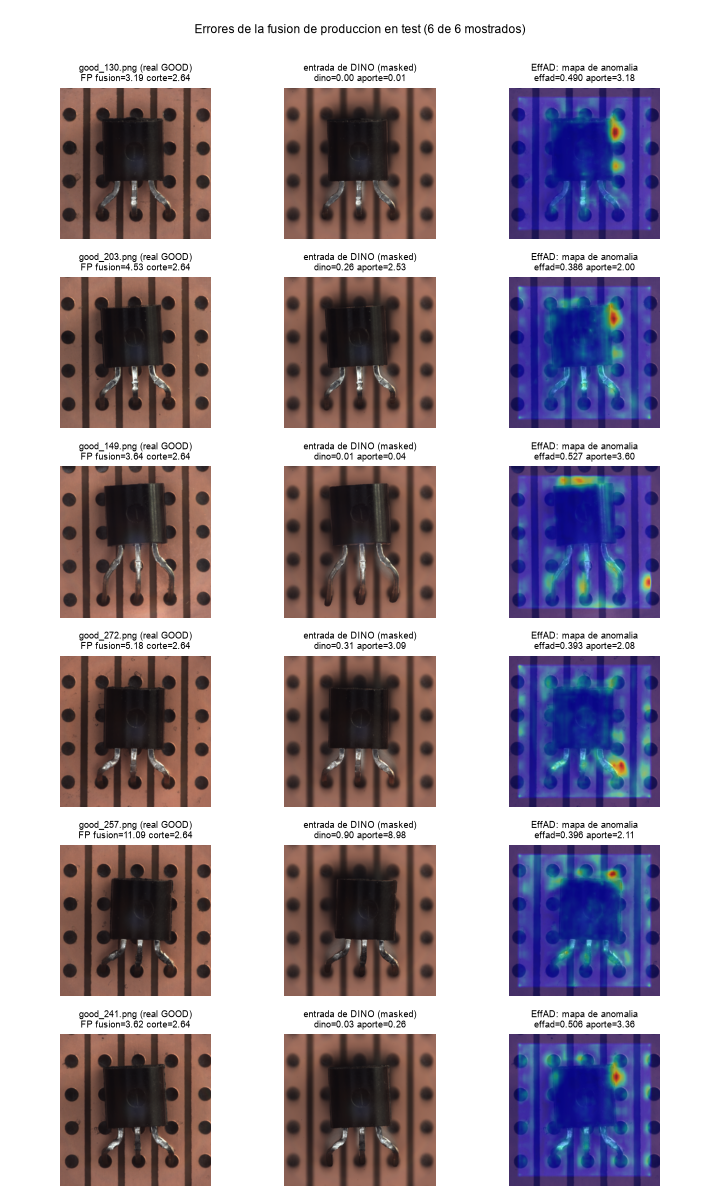

In [ ]:
# §11b Proposito: mini reporte de los errores de la decision de produccion (brazo prod de §11) en test.
tic("errores_prod")
_fz = np.load(fusion_npz)
_cal = {k: float(_fz["oof_" + k] if "oof_" + k in _fz else _fz[k]) for k in ("alpha", "cut", "md", "id", "me", "ie")}  # misma calibracion que §11 e infer()
_d, _e = _fz["dino"], _fz["effad"]
_td = _cal["alpha"] * (_d - _cal["md"]) / _cal["id"]
_te_ = (1 - _cal["alpha"]) * (_e - _cal["me"]) / _cal["ie"]
_f = _td + _te_
_names, _y, _tix = list(_fz["fnames"]), _fz["y"].astype(int), _fz["test_idx"]
_area = dict(zip(sam_masks.filename, sam_masks.area))
_pathof = dict(zip(df_files.filename, df_files.path))
_wrong = [int(_i) for _i in _tix if int(_f[_i] >= _cal["cut"]) != _y[_i]]
_rows = []
for _i in _wrong:
    _rows.append({"filename": _names[_i], "real": "BAD" if _y[_i] else "GOOD",
                  "error": "FN (BAD perdida)" if _y[_i] else "FP (falsa alarma)",
                  "dino": round(float(_d[_i]), 3), "effad": round(float(_e[_i]), 3),
                  "aporte_dino": round(float(_td[_i]), 2), "aporte_effad": round(float(_te_[_i]), 2),
                  "fusion": round(float(_f[_i]), 2), "corte": round(_cal["cut"], 3),
                  "margen": round(float(_f[_i] - _cal["cut"]), 2), "area_mascara": round(float(_area[_names[_i]]), 3)})
errores_prod = pd.DataFrame(_rows)
_ngood, _nbad = int((_y[_tix] == 0).sum()), int((_y[_tix] == 1).sum())
_nfp = int((_y[_wrong] == 0).sum()) if _wrong else 0
_nfn = len(_wrong) - _nfp
_lines = ["#### Resultado en test",
          "- %d GOOD + %d BAD, corte prod = %.3f (alpha OOF = %.2f)." % (_ngood, _nbad, _cal["cut"], _cal["alpha"]),
          "- **%d falsas alarmas (FP)** de %d GOOD y **%d BAD perdidas (FN)** de %d BAD." % (_nfp, _ngood, _nfn, _nbad)]
if _nfp:
    _fpdf = errores_prod[errores_prod.error.str.startswith("FP")]
    _dom = int((_fpdf.aporte_effad > _fpdf.aporte_dino).sum())
    _lines.append("- En los FP el brazo que mas empuja hacia BAD es EffAD en %d y DINO en %d. Margen medio sobre el corte: %.2f." % (_dom, len(_fpdf) - _dom, _fpdf.margen.mean()))
if _nfn:
    _lines.append("- BAD perdidas: " + ", ".join(errores_prod[errores_prod.error.str.startswith("FN")].filename))
_items = [mo.md("\n".join(_lines))]
if _wrong:
    _ckpt = sorted(glob.glob(str(MODELS_DIR / "effad/**/*.ckpt"), recursive=True), key=os.path.getmtime)[-1]
    _dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    _em = EfficientAd.load_from_checkpoint(_ckpt, map_location="cpu").eval().to(_dev)
    _shown = _wrong[:12]
    _fig, _ax = plt.subplots(len(_shown), 3, figsize=(9, 2.5 * len(_shown)), squeeze=False)
    _fig.patch.set_facecolor("white")
    for _k, _i in enumerate(_shown):
        _fn = _names[_i]
        _im0 = Image.open(_pathof[_fn]).convert("RGB").resize((256, 256))
        _xb = torch.from_numpy(np.asarray(_im0, dtype="float32") / 255.0).permute(2, 0, 1).unsqueeze(0).to(_dev)
        with torch.inference_mode():
            _amap = _em(_xb).anomaly_map.squeeze().cpu().numpy()
        _row = _ax[_k]
        _row[0].imshow(_im0)
        _row[0].set_title("%s (real %s)\n%s fusion=%.2f corte=%.2f" % (_fn, "BAD" if _y[_i] else "GOOD", "FN" if _y[_i] else "FP", _f[_i], _cal["cut"]), fontsize=8, color="black")
        _row[1].imshow(variant_image(_fn, _pathof[_fn], "masked").resize((256, 256)))
        _row[1].set_title("entrada de DINO (masked)\ndino=%.2f aporte=%.2f" % (_d[_i], _td[_i]), fontsize=8, color="black")
        _row[2].imshow(_im0)
        _row[2].imshow(_amap, cmap="jet", alpha=0.5)
        _row[2].set_title("EffAD: mapa de anomalia\neffad=%.3f aporte=%.2f" % (_e[_i], _te_[_i]), fontsize=8, color="black")
        [_a.axis("off") for _a in _row]
    _fig.suptitle("Errores de la fusion de produccion en test (%d de %d mostrados)" % (len(_shown), len(_wrong)), fontsize=11, color="black")
    _fig.tight_layout(rect=(0, 0, 1, 0.98))
    _png = FIG_DIR / "errores_fusion_prod.png"
    _fig.savefig(_png, dpi=80)
    plt.close(_fig)
    _em.to("cpu")
    del _em
    torch.cuda.empty_cache()
    print("saved", _png.name)
    _items += [mo.ui.table(errores_prod, selection=None, pagination=False), mo.image(str(_png))]
toc("errores_prod")
mo.vstack(_items)

### §12 MLflow: params, metricas, ONNXs, figuras y fingerprint en un run

In [ ]:
# §12 Proposito: deja todo trazado en MLflow (reproducible por fingerprint), estudiante incluido.
tic("mlflow_final")

import mlflow

mlflow.set_tracking_uri(MLFLOW_URI)
mlflow.set_experiment(MLFLOW_EXPERIMENT)
with mlflow.start_run(run_name=f"{PROJECT_NAME}_prod") as _run:
    mlflow.log_params({"backbone": BACKBONE_ID, "dino_variant": DINO_VARIANT, "effad_variant": EFFAD_VARIANT,
                        "effad_size": EFFAD_SIZE, "steps": STEPS, "seed": SEED, "fingerprint": fingerprint,
                        "segmenter": EVIT_NAME, "segmenter_precision": "fp32", "segmenter_side": EVIT_SIDE,
                        "distill_epochs": EVIT_EPOCHS, "distill_batch": EVIT_BATCH, "distill_lr": EVIT_LR,
                        "distill_target": "teacher_binary_mask", "distill_prompt": "fixed_full_frame_1024"})
    for _, _r in eval_df.iterrows():
        mlflow.log_metrics({f"{_r.method}_recall": _r.recall, f"{_r.method}_far": _r.far, f"{_r.method}_auroc": _r.auroc})
    mlflow.log_metrics({"student_iou": float(student_quality.iou.mean()),
                        "student_dice": float(student_quality.dice.mean()),
                        "student_boundary_f1": float(student_quality.boundary_f1.mean()),
                        "student_empty_rate": float(student_quality.empty_mask.mean()),
                        **{"student_" + _k: float(_v) for _k, _v in student_speed.items() if isinstance(_v, (int, float))}})
    for _, _e in distill_log.iterrows():
        mlflow.log_metrics({"distill_train_loss": float(_e.train_loss), "distill_val_loss": float(_e.val_loss),
                            "distill_train_dice": float(_e.train_dice), "distill_val_dice": float(_e.val_dice)},
                           step=int(_e.epoch) - 1)
    _artifact_files = [MODELS_DIR / "dino.npz", MODELS_DIR / "fusion.npz", calib_oof_npz,
                        MODELS_DIR / "eval.csv", eval_bootstrap_csv, MODELS_DIR / "dino_logreg.onnx",
                        MODELS_DIR / "effad.onnx", MODELS_DIR / "good_mean.npy",
                        MODELS_DIR / "student" / "best.pt", MODELS_DIR / "student" / "light_logs.csv",
                        MODELS_DIR / "student" / "quality.csv", MODELS_DIR / "student" / "speed.json",
                        MODELS_DIR / "student" / "masks.csv", MODELS_DIR / "teacher" / "masks.csv"]
    for _f in _artifact_files:
        mlflow.log_artifact(str(_f))
    for _g in FIG_DIR.glob("*.png"):
        mlflow.log_artifact(str(_g))
    mlflow.set_tag("fingerprint", fingerprint)
    mlflow.set_tag("segmenter", EVIT_NAME)
    mlflow_run_id = _run.info.run_id
print("mlflow listo, run_id:", mlflow_run_id)
toc("mlflow_final")

[15:41:21] inicio mlflow_final
mlflow listo, run_id: 4c074bf0a5264d06a880b1a6ae3cba8c
[15:41:23] fin mlflow_final (1.8s)


### §13 infer(): runtime de produccion end-to-end con el estudiante (sin SAM), solo GPU

In [ ]:
# §13 Proposito: UNICA implementacion de la inferencia de produccion. Solo camino GPU
# (benchmark ONNX-CPU/NVTX quedo fuera de alcance, vive en industrial_profile.py).
assert calib_oof_npz.exists(), "corre §10 (calib_oof) antes de construir infer(): debe nacer prefiriendo OOF"
import contextlib as _ctx8
import time as _time8

import onnxruntime as _ort

try:
    release_runtime()
except NameError:
    pass
tic("runtime")
_dev8 = torch.device("cuda" if torch.cuda.is_available() else "cpu")
_fz8 = np.load(fusion_npz)
_cal8 = {k: float(_fz8["oof_" + k] if "oof_" + k in _fz8 else _fz8[k]) for k in ("alpha", "cut", "md", "id", "me", "ie")}
_sess_logreg = _ort.InferenceSession(str(MODELS_DIR / "dino_logreg.onnx"))
_effad_ckpt8 = sorted(glob.glob(str(MODELS_DIR / "effad/**/*.ckpt"), recursive=True), key=os.path.getmtime)[-1]
_effad_gpu = EfficientAd.load_from_checkpoint(_effad_ckpt8, map_location="cpu").eval().to(_dev8)
_proc8 = AutoImageProcessor.from_pretrained(BACKBONE_ID)
_dino8 = AutoModel.from_pretrained(BACKBONE_ID).eval().to(_dev8)
_student8 = load_student(student_ckpt).to(_dev8).float().eval()
print(f"runtime: estudiante {EVIT_SIDE}px + dinov2 + effad-{EFFAD_SIZE} en {_dev8}; ckpt {_effad_ckpt8}")

@_ctx8.contextmanager
def _stage(name, records, collect=False):
    if collect:
        torch.cuda.synchronize()
        _t0 = _time8.perf_counter()
    yield
    if collect:
        torch.cuda.synchronize()
        records[name] = (_time8.perf_counter() - _t0) * 1000

def infer(path, collect=False, effad="gpu"):
    """Pipeline de produccion: estudiante -> mascara -> DINO-masked + EffAD -> fusion."""
    _st = {}
    with torch.inference_mode():
        with _stage("load_decode", _st, collect):
            with Image.open(path) as _op:
                _im = _op.convert("RGB")
            _arr = np.asarray(_im)
        with _stage("student_predict", _st, collect):
            _x, _geo = prepare_tensor(_arr, EVIT_SIDE)
            _prob = _student8(_x).float().sigmoid()
        with _stage("mask_restore", _st, collect):
            _mask = restore_mask(_prob, _geo)
        with _stage("mask_crop", _st, collect):
            # Mismo QC que el batch (§6): si la mascara no es creible, va la foto original.
            _area = float(_mask.mean())
            _bb = mask_to_bbox(_mask)
            _edge = bool(_mask[0, :].any() or _mask[-1, :].any() or _mask[:, 0].any() or _mask[:, -1].any())
            _fallback = _bb is None or _area < MIN_MASK_AREA_RATIO or _area > MAX_MASK_AREA_RATIO or _edge
            if _fallback:
                _masked = _im
            else:
                _masked = build_masked(_im, _mask)
        with _stage("dino_preprocess", _st, collect):
            _in = _proc8(images=_masked, size={"height": 224, "width": 224}, return_tensors="pt")
        with _stage("dino_h2d", _st, collect):
            _in = {k: v.to(_dev8) for k, v in _in.items()}
        with _stage("dinov2", _st, collect):
            _out = _dino8(**_in).last_hidden_state[:, 0, :]
        with _stage("dino_d2h", _st, collect):
            _cls = _out.cpu().numpy()
        with _stage("logreg", _st, collect):
            _pdino = float(_sess_logreg.run(None, {"input": _cls.astype("float32")})[1][0][1])
        with _stage("effad_preprocess", _st, collect):
            _xb = torch.from_numpy(np.asarray(_im.resize((256, 256)), dtype="float32") / 255.0).permute(2, 0, 1).unsqueeze(0)
        with _stage("effad_gpu", _st, collect):
            assert effad == "gpu", "este runtime solo corre el camino GPU (ver industrial_profile.py para ONNX-CPU)"
            _peff = float(_effad_gpu(_xb.to(_dev8)).pred_score.flatten()[0])
        with _stage("fusion", _st, collect):
            _fused = float(_cal8["alpha"] * (_pdino - _cal8["md"]) / _cal8["id"]
                           + (1 - _cal8["alpha"]) * (_peff - _cal8["me"]) / _cal8["ie"])
            _bad = bool(_fused >= _cal8["cut"])
    return {"dino": _pdino, "effad": _peff, "fused": _fused, "bad": _bad,
            "mask_area": _area, "bbox": _bb, "fallback": _fallback, "stages_ms": _st}

def reference_infer(path):
    # Transcripcion independiente del pipeline (sin etapas): sirve para probar que infer() no
    # cambia el resultado. Usa los MISMOS modelos residentes.
    with torch.inference_mode():
        with Image.open(path) as _op:
            _im = _op.convert("RGB")
        _x, _geo = prepare_tensor(np.asarray(_im), EVIT_SIDE)
        _mask = restore_mask(_student8(_x).float().sigmoid(), _geo)
        _area, _bb = float(_mask.mean()), mask_to_bbox(_mask)
        _edge = bool(_mask[0, :].any() or _mask[-1, :].any() or _mask[:, 0].any() or _mask[:, -1].any())
        if _bb is None or _area < MIN_MASK_AREA_RATIO or _area > MAX_MASK_AREA_RATIO or _edge:
            _masked = _im
        else:
            _masked = build_masked(_im, _mask)
        _in = _proc8(images=_masked, size={"height": 224, "width": 224}, return_tensors="pt")
        _cls = _dino8(**{k: v.to(_dev8) for k, v in _in.items()}).last_hidden_state[:, 0, :].cpu().numpy()
        _pdino = float(_sess_logreg.run(None, {"input": _cls.astype("float32")})[1][0][1])
        _xb = torch.from_numpy(np.asarray(_im.resize((256, 256)), dtype="float32") / 255.0).permute(2, 0, 1).unsqueeze(0)
        _peff = float(_effad_gpu(_xb.to(_dev8)).pred_score.flatten()[0])
        _fused = float(_cal8["alpha"] * (_pdino - _cal8["md"]) / _cal8["id"]
                       + (1 - _cal8["alpha"]) * (_peff - _cal8["me"]) / _cal8["ie"])
    return {"dino": _pdino, "effad": _peff, "fused": _fused,
            "bad": bool(_fused >= _cal8["cut"]), "mask_area": _area, "bbox": _bb}

def release_runtime():
    _student8.to("cpu")
    _dino8.to("cpu")
    _effad_gpu.to("cpu")
    import gc as _gc8

    _gc8.collect()
    torch.cuda.empty_cache()
    print("runtime en CPU, VRAM:", round(torch.cuda.memory_allocated() / 1e9, 3), "GB")

def restore_runtime():
    _student8.to(_dev8)
    _dino8.to(_dev8)
    _effad_gpu.to(_dev8)
    print("runtime de vuelta en", _dev8)

toc("runtime")

[15:41:23] inicio runtime


Loading weights: 100%|##########| 223/223 [00:00<00:00, 985.98it/s]
C:\Users\user\Documents\qc-vision-inspector\models\transistor_binary\sam_distillation\vendor\efficientvit\efficientvit\models\nn\ops.py:395: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  @autocast(enabled=False)


runtime: estudiante 512px + dinov2 + effad-medium en cuda; ckpt models\transistor_binary\industrial_master_v2\effad\EfficientAd\none\none\v0\weights\lightning\model.ckpt
[15:41:26] fin runtime (3.0s)


In [ ]:
# §13 Proposito: decide 1 GOOD + 1 BAD nuevas con el desglose por etapa (muestra rapida, no metrica).
tic("infer_ejemplo")
_cut8 = float(np.load(fusion_npz)["cut"])
for _lab in ("good", "bad"):
    _row = test_files[test_files.label == _lab].iloc[0]
    _out = infer(_row.path, collect=True)
    print(_lab, _row.filename, "->", "BAD" if _out["bad"] else "GOOD",
          "fused=%.3f" % _out["fused"], "stages_ms=%s" % {k: round(v, 1) for k, v in _out["stages_ms"].items()}, flush=True)
toc("infer_ejemplo")

[15:41:26] inicio infer_ejemplo


C:\Users\user\AppData\Local\Temp\marimo_39180\__marimo__cell_iLit_.py:43: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  _px = torch.from_numpy(image).to("cuda").permute(2, 0, 1).unsqueeze(0)


good good_228.png -> GOOD fused=-0.005 stages_ms={'load_decode': 32.9, 'student_predict': 189.9, 'mask_restore': 1.0, 'mask_crop': 19.3, 'dino_preprocess': 8.2, 'dino_h2d': 0.3, 'dinov2': 24.9, 'dino_d2h': 0.3, 'logreg': 0.2, 'effad_preprocess': 6.9, 'effad_gpu': 48.3, 'fusion': 0.0}
bad bad_024.png -> BAD fused=13.348 stages_ms={'load_decode': 33.4, 'student_predict': 45.4, 'mask_restore': 0.8, 'mask_crop': 21.1, 'dino_preprocess': 5.6, 'dino_h2d': 0.3, 'dinov2': 15.8, 'dino_d2h': 0.2, 'logreg': 0.1, 'effad_preprocess': 6.3, 'effad_gpu': 42.7, 'fusion': 0.0}
[15:41:26] fin infer_ejemplo (0.5s)


### §14 Chequeo de equivalencia: infer() debe reproducir fusion.npz en una muestra de test

In [ ]:
# §14 Proposito: assert duro de que infer() reproduce los scores de fusion.npz antes de confiar
# en §15/§16. Generaliza "equiv63": muestra EQUIV_N_SAMPLES fotos de test, no el dataset entero.
tic("equiv_check")
_fz6 = np.load(fusion_npz)
_pos6 = {f: i for i, f in enumerate(_fz6["fnames"])}
_cal6 = {k: float(_fz6["oof_" + k] if "oof_" + k in _fz6 else _fz6[k]) for k in ("alpha", "cut", "md", "id", "me", "ie")}  # misma calibracion que infer(): OOF con fallback a in-sample
_rng14 = np.random.default_rng(SEED)
_n_sample = min(EQUIV_N_SAMPLES, len(test_files))
_sample = test_files.iloc[_rng14.choice(len(test_files), size=_n_sample, replace=False)]
_r63 = []
for _rk, _rr in enumerate(_sample.itertuples()):
    _o63 = infer(_rr.path)
    _i63 = _pos6[_rr.filename]
    _tol63 = {"dino": 1e-6, "effad": 1e-2, "fused": 1e-2}  # EffAD-GPU no es bit-determinista entre batch y frame; DINO si
    _d6, _e6 = float(_fz6["dino"][_i63]), float(_fz6["effad"][_i63])
    _f6 = _cal6["alpha"] * (_d6 - _cal6["md"]) / _cal6["id"] + (1 - _cal6["alpha"]) * (_e6 - _cal6["me"]) / _cal6["ie"]
    _m63 = (abs(_o63["dino"] - _d6) < _tol63["dino"] and abs(_o63["effad"] - _e6) < _tol63["effad"]
            and abs(_o63["fused"] - _f6) < _tol63["fused"] and _o63["bad"] == bool(_f6 >= _cal6["cut"]))
    _r63.append({"filename": _rr.filename, "label": _rr.label, "match": _m63,
                 "dino": _o63["dino"], "effad": _o63["effad"], "fused": _o63["fused"], "bad": _o63["bad"]})
equivalence_table = pd.DataFrame(_r63)
_y63 = (equivalence_table.label == "bad").to_numpy(int)
_pb63 = equivalence_table.bad.to_numpy(int)
print("coinciden %d/%d (muestra de %d)" % (equivalence_table.match.sum(), len(equivalence_table), _n_sample), flush=True)
equivalence_ok = bool(equivalence_table.match.all())
assert equivalence_ok, "infer() diverge de eval en %d fotos" % int((~equivalence_table.match).sum())
equivalence_table.to_csv(MODELS_DIR / "equivalencia.csv", index=False)
print("saved equivalencia.csv")
toc("equiv_check")

[15:41:26] inicio equiv_check
coinciden 20/20 (muestra de 20)
saved equivalencia.csv
[15:41:29] fin equiv_check (2.5s)


### §15 Latencia: chequeo rapido de velocidad GPU (sin Nsight/NVTX, eso vive en industrial_profile.py)

In [ ]:
# §15 Proposito: wall-clock de infer() en GPU sobre N imagenes, nada mas. Gate: solo si §14 paso.
import time as _time15
assert equivalence_ok, "no se mide latencia de un runtime que no reproduce las decisiones esperadas"
tic("latency_check")
_n15 = min(LATENCY_N_IMAGES, len(test_files))
_imgs15 = test_files.sample(n=_n15, random_state=0)
for _k15 in range(min(LATENCY_N_WARMUP, len(_imgs15))):
    infer(_imgs15.iloc[_k15 % len(_imgs15)].path)
torch.cuda.synchronize()
_times15 = []
for _row15 in _imgs15.itertuples():
    torch.cuda.synchronize()
    _t0_15 = _time15.perf_counter()
    infer(_row15.path)
    torch.cuda.synchronize()
    _times15.append((_time15.perf_counter() - _t0_15) * 1000)
_arr15 = np.array(_times15)
latency_summary = {"n": len(_arr15), "median_ms": float(np.median(_arr15)), "p95_ms": float(np.quantile(_arr15, 0.95)),
                    "mean_ms": float(_arr15.mean()), "min_ms": float(_arr15.min()), "max_ms": float(_arr15.max()),
                    "fps_secuencial": float(1000 / np.median(_arr15))}
pd.DataFrame([latency_summary]).to_csv(MODELS_DIR / "latency_check.csv", index=False)
print("latencia infer() GPU: mediana %.1f ms p95 %.1f ms (%.2f fps secuencial), n=%d" % (
    latency_summary["median_ms"], latency_summary["p95_ms"], latency_summary["fps_secuencial"], latency_summary["n"]), flush=True)
toc("latency_check")

[15:41:29] inicio latency_check
latencia infer() GPU: mediana 118.8 ms p95 125.9 ms (8.42 fps secuencial), n=20
[15:41:32] fin latency_check (3.0s)


### §16 Piloto: infer() congelado sobre fotos nuevas sin etiquetas (no reajusta nada)

In [ ]:
# §16 Proposito: piloto con fotos nuevas sin etiquetas (infer congelado + rejilla). No reajustar el corte.
NEW_DIR = Path("data/new") / PROJECT_NAME
tic("piloto")
import glob as _gbp
_imgs = sorted(f for f in _gbp.glob(str(NEW_DIR / "*")) if Path(f).is_file())
_test_far = float(eval_df.set_index("method").loc["fused", "far"])
piloto_df = None
if not _imgs:
    _msg = ("criterio de piloto: 0 misses en BAD nuevas, recall >= %.2f, "
            "FAR <= %.3f (umbral) / %.3f (FAR medido en test)") % (MIN_RECALL_FOR_PILOT, MAX_FAR_FOR_PILOT, _test_far)
    print("sin fotos nuevas en %s: %s" % (NEW_DIR, _msg))
    mo.md(f"**Sin fotos nuevas en `{NEW_DIR}`.** {_msg}")
else:
    _prow = []
    with torch.inference_mode():
        for _fp in _imgs:
            _o23 = infer(_fp)
            _prow.append({"foto": Path(_fp).name, "dino": round(_o23["dino"], 3), "effad": round(_o23["effad"], 4),
                           "fusion": round(_o23["fused"], 2), "pred": "BAD" if _o23["bad"] else "GOOD"})
            print("%s -> %s (f=%.2f)" % (_prow[-1]["foto"], _prow[-1]["pred"], _prow[-1]["fusion"]), flush=True)
    piloto_df = pd.DataFrame(_prow)
    print("piloto: %d fotos, %d BAD / %d GOOD" % (len(piloto_df), int((piloto_df.pred == "BAD").sum()), int((piloto_df.pred == "GOOD").sum())))
    _f23, _ax23 = plt.subplots(len(piloto_df), 2, figsize=(9, 2.6 * len(piloto_df)), squeeze=False)
    _f23.patch.set_facecolor("white")
    for _k23, _fp in enumerate(_imgs):
        _im23 = Image.open(_fp).convert("RGB")
        _ax23[_k23][0].imshow(_im23)
        _ax23[_k23][0].set_title(Path(_fp).name, fontsize=8, color="black")
        _ax23[_k23][1].imshow(_im23)
        _ax23[_k23][1].set_title("%s d=%.3f e=%.4f f=%.2f" % (piloto_df.pred[_k23], piloto_df.dino[_k23], piloto_df.effad[_k23], piloto_df.fusion[_k23]), fontsize=8, color="black")
        [_aa.axis("off") for _aa in _ax23[_k23]]
    _f23.suptitle("Piloto: predicciones congeladas (sin reajustar corte)", fontsize=11, color="black")
    _f23.tight_layout(); _f23.savefig(FIG_DIR / "piloto.png", dpi=90)
    print("saved piloto.png")
    mo.image(str(FIG_DIR / "piloto.png"))
toc("piloto")

[15:41:32] inicio piloto
sin fotos nuevas en data\new\transistor_binary: criterio de piloto: 0 misses en BAD nuevas, recall >= 0.98, FAR <= 0.080 (umbral) / 0.127 (FAR medido en test)
[15:41:32] fin piloto (0.0s)


### §17 Resumen final: el veredicto en pocas lineas
`PILOT CANDIDATE` sale solo si `recall >= MIN_RECALL_FOR_PILOT` y
`FAR <= MAX_FAR_FOR_PILOT` (umbrales de §1), nunca de numeros fijos de un dataset anterior.

In [ ]:
# §17 Proposito: veredicto final legible, reemplaza a "cierre" (que en el notebook fuente
# dependia de Nsight/ablacion/TF32/fast_batch — todo eso fuera de alcance aqui).
_ocf = dict(np.load(calib_oof_npz))
_fused_row = eval_df.set_index("method").loc["fused"]
_md17 = []
_md17.append(f"## Resumen — {PROJECT_NAME}")
_md17.append(f"Dataset: {(df_files.label == 'good').sum()} GOOD + {(df_files.label == 'bad').sum()} BAD.")
_md17.append("Pipeline: SAM teacher -> estudiante EfficientViT-SAM destilado -> DINOv2-masked + EfficientAd -> fusion -> calibracion OOF.")
_md17.append("## Metricas test (corte q95-train)")
for _, _r in eval_df.iterrows():
    _md17.append("- %s: AUROC %.4f * recall %.3f * FAR %.3f * precBAD %.3f * F1BAD %.3f" % (_r.method, _r.auroc, _r.recall, _r.far, _r.prec_bad, _r.f1_bad))
_md17.append("## Calibracion OOF (train)")
_md17.append("alpha=%.2f recall=%.3f far=%.3f (in-sample distinto: ver §9/§10)" % (float(_ocf["alpha"]), float(_ocf["rec"]), float(_ocf["far"])))
_md17.append("## Segmentador destilado (acuerdo con teacher)")
_md17.append("IoU %.4f / Dice %.4f / borde F1 %.4f / vacias %.3f. Red %.1f ms, segmento %.1f ms, teacher %.0f ms -> %.1fx." % (
    student_quality.iou.mean(), student_quality.dice.mean(), student_quality.boundary_f1.mean(), student_quality.empty_mask.mean(),
    student_speed["fwd_cuda_ms_median"], student_speed["seg_ms_median"], student_speed["teacher_seg_ms_median"], student_speed["speedup_vs_teacher"]))
if piloto_df is not None:
    _md17.append("## Piloto: %d fotos, %d BAD / %d GOOD" % (len(piloto_df), int((piloto_df.pred == "BAD").sum()), int((piloto_df.pred == "GOOD").sum())))
else:
    _md17.append("## Piloto: sin fotos nuevas todavia (ver §16)")
_sel_recall, _sel_far = float(_fused_row.recall), float(_fused_row.far)
_veredicto = "PILOT CANDIDATE" if _sel_recall >= MIN_RECALL_FOR_PILOT and _sel_far <= MAX_FAR_FOR_PILOT else "NO PILOT (revisar umbrales)"
_md17.append(f"## Veredicto: **{_veredicto}**")
_md17.append(f"(recall={_sel_recall:.3f} vs MIN_RECALL_FOR_PILOT={MIN_RECALL_FOR_PILOT:.2f}; FAR={_sel_far:.3f} vs MAX_FAR_FOR_PILOT={MAX_FAR_FOR_PILOT:.2f})")
print("\n".join(_md17))
mo.md("\n".join(_md17))

## Resumen — transistor_binary
Dataset: 273 GOOD + 40 BAD.
Pipeline: SAM teacher -> estudiante EfficientViT-SAM destilado -> DINOv2-masked + EfficientAd -> fusion -> calibracion OOF.
## Metricas test (corte q95-train)
- dino: AUROC 0.9886 * recall 1.000 * FAR 0.073 * precBAD 0.667 * F1BAD 0.800
- effad: AUROC 0.9795 * recall 0.875 * FAR 0.127 * precBAD 0.500 * F1BAD 0.636
- fused: AUROC 0.9886 * recall 1.000 * FAR 0.127 * precBAD 0.533 * F1BAD 0.696
## Calibracion OOF (train)
alpha=0.20 recall=1.000 far=0.050 (in-sample distinto: ver §9/§10)
## Segmentador destilado (acuerdo con teacher)
IoU 0.9639 / Dice 0.9796 / borde F1 0.8358 / vacias 0.000. Red 20.1 ms, segmento 23.9 ms, teacher 1600 ms -> 66.8x.
## Piloto: sin fotos nuevas todavia (ver §16)
## Veredicto: **NO PILOT (revisar umbrales)**
(recall=1.000 vs MIN_RECALL_FOR_PILOT=0.98; FAR=0.127 vs MAX_FAR_FOR_PILOT=0.08)


## Resumen — transistor_binary
Dataset: 273 GOOD + 40 BAD.
Pipeline: SAM teacher -> estudiante EfficientViT-SAM destilado -> DINOv2-masked + EfficientAd -> fusion -> calibracion OOF.
## Metricas test (corte q95-train)
- dino: AUROC 0.9886 * recall 1.000 * FAR 0.073 * precBAD 0.667 * F1BAD 0.800
- effad: AUROC 0.9795 * recall 0.875 * FAR 0.127 * precBAD 0.500 * F1BAD 0.636
- fused: AUROC 0.9886 * recall 1.000 * FAR 0.127 * precBAD 0.533 * F1BAD 0.696
## Calibracion OOF (train)
alpha=0.20 recall=1.000 far=0.050 (in-sample distinto: ver §9/§10)
## Segmentador destilado (acuerdo con teacher)
IoU 0.9639 / Dice 0.9796 / borde F1 0.8358 / vacias 0.000. Red 20.1 ms, segmento 23.9 ms, teacher 1600 ms -> 66.8x.
## Piloto: sin fotos nuevas todavia (ver §16)
## Veredicto: **NO PILOT (revisar umbrales)**
(recall=1.000 vs MIN_RECALL_FOR_PILOT=0.98; FAR=0.127 vs MAX_FAR_FOR_PILOT=0.08)